In [1]:
# RELEASE 3.2 - self-contained frozen calibration initialization
import json
from pathlib import Path

FROZEN_RELEASE_3_2 = {
  "source": "Verified Mendeley Data Version 2 parent snapshot",
  "parent_dataset_doi": "10.17632/tf56mbyg69.2",
  "parent_snapshot_sha256": "8d2a0c8f8869779d5e7996940ba6218030daa5ac6376a08c55bd5407fbc5ea7e",
  "parent_rows": 612,
  "parent_unique_rows": 612,
  "fall_proportion": 0.1388888888888889,
  "condition_probabilities": {
    "normal": 0.3533834586466165,
    "borderline_fever": 0.16165413533834586,
    "borderline_hypoxia": 0.16165413533834586,
    "hypertension_episode": 0.16165413533834586,
    "hypotension_episode": 0.16165413533834586
  },
  "physiological_calibration": {
    "heart_rate": {
      "robust_center": 84.13,
      "raw_robust_scale": 35.029651593773174,
      "scale_cap": 12.0,
      "scale_used": 12.0
    },
    "spo2": {
      "robust_center": 93.33500000000001,
      "raw_robust_scale": 6.308376575240913,
      "scale_cap": 2.5,
      "scale_used": 2.5
    },
    "temperature": {
      "robust_center": 36.92,
      "raw_robust_scale": 0.41697553743513716,
      "scale_cap": 0.35,
      "scale_used": 0.35
    },
    "hrv": {
      "robust_center": 27.9,
      "raw_robust_scale": 12.807635285396588,
      "scale_cap": 10.0,
      "scale_used": 10.0
    }
  },
  "acceleration_calibration": {
    "source_unit": "m/s2",
    "source_median": 9.77,
    "target_unit": "g",
    "conversion_factor": 0.10197162129779283
  },
  "gyroscope_calibration": {
    "source_unit": "unresolved",
    "target_unit": "degrees_per_second",
    "physical_comparison": "excluded"
  }
}

FROZEN_CALIBRATION_PATH = Path('/content/release_3_2_frozen_calibration.json')
FROZEN_CALIBRATION_PATH.write_text(
    json.dumps(FROZEN_RELEASE_3_2, indent=2), encoding='utf-8'
)
print('Release 3.2 frozen calibration JSON initialized.')
print('Default generation is parent-independent.')


Release 3.2 frozen calibration JSON initialized.
Default generation is parent-independent.


In [2]:
# RELEASE 3.2 - optional, non-blocking parent-source audit controls
RUN_PARENT_SOURCE_AUDIT = False
BASE_CSV_PATH = '/content/healthmonitoringandfalldetection.csv'
EXPECTED_PARENT_SHA256 = '8d2a0c8f8869779d5e7996940ba6218030daa5ac6376a08c55bd5407fbc5ea7e'

assert abs(sum(FROZEN_RELEASE_3_2['condition_probabilities'].values()) - 1.0) < 1e-12
assert FROZEN_RELEASE_3_2['parent_snapshot_sha256'] == EXPECTED_PARENT_SHA256
print('Frozen Release 3.2 calibration validated.')
print('Parent CSV audit is optional and never supplies generation parameters.')

print('Single-input mode: parent CSV audit disabled; frozen calibration will be used.')


Frozen Release 3.2 calibration validated.
Parent CSV audit is optional and never supplies generation parameters.
Single-input mode: parent CSV audit disabled; frozen calibration will be used.


In [3]:
# SINGLE INPUT CELL - locate or upload the exact SisFall archive under any filename
from pathlib import Path
import hashlib

SISFALL_EXPECTED_SIZE_BYTES = 232407821
SISFALL_EXPECTED_SHA256 = '7f0dd1583e39fee0f402a6855976eb12517f7eaecdacce871d5b3421793ad665'

def file_sha256(path, chunk_size=8 * 1024 * 1024):
    digest = hashlib.sha256()
    with open(path, 'rb') as stream:
        for chunk in iter(lambda: stream.read(chunk_size), b''):
            digest.update(chunk)
    return digest.hexdigest()

def find_exact_sisfall_archive():
    candidates = sorted(Path('/content').glob('*.zip'))
    checked = []
    for candidate in candidates:
        size = candidate.stat().st_size
        # Hash only matching-size candidates; this avoids reading unrelated large ZIP files.
        observed_hash = file_sha256(candidate) if size == SISFALL_EXPECTED_SIZE_BYTES else None
        checked.append((candidate.name, size, observed_hash))
        if size == SISFALL_EXPECTED_SIZE_BYTES and observed_hash == SISFALL_EXPECTED_SHA256:
            return candidate, checked
    return None, checked

SISFALL_ARCHIVE_PATH, checked_archives = find_exact_sisfall_archive()

if SISFALL_ARCHIVE_PATH is None:
    from google.colab import files
    print('Upload the single supplied SisFall ZIP now. Its filename may be unchanged or random.')
    uploaded = files.upload()
    if not uploaded:
        raise FileNotFoundError('No ZIP file was uploaded.')
    SISFALL_ARCHIVE_PATH, checked_archives = find_exact_sisfall_archive()

if SISFALL_ARCHIVE_PATH is None:
    details = '\n'.join(
        f'  {name}: {size:,} bytes; SHA-256={digest or "not calculated (size differs)"}'
        for name, size, digest in checked_archives
    ) or '  No ZIP candidates found in /content.'
    raise ValueError(
        'The exact SisFall archive was not found.\n'
        f'Expected size: {SISFALL_EXPECTED_SIZE_BYTES:,} bytes\n'
        f'Expected SHA-256: {SISFALL_EXPECTED_SHA256}\n'
        f'Checked archives:\n{details}'
    )

print('PASS: exact SisFall archive selected.')
print('Selected path:', SISFALL_ARCHIVE_PATH)
print('Size:', f'{SISFALL_ARCHIVE_PATH.stat().st_size:,}', 'bytes')
print('SHA-256:', file_sha256(SISFALL_ARCHIVE_PATH))
print('No parent CSV is required or used in this single-input run.')

Upload the single supplied SisFall ZIP now. Its filename may be unchanged or random.


Saving SisFall_dataset.zip to SisFall_dataset.zip
PASS: exact SisFall archive selected.
Selected path: /content/SisFall_dataset.zip
Size: 232,407,821 bytes
SHA-256: 7f0dd1583e39fee0f402a6855976eb12517f7eaecdacce871d5b3421793ad665
No parent CSV is required or used in this single-input run.


# Refined Literature-Informed Synthetic Elderly Dataset — Release 3.2

This single-input publication notebook requires only the exact SisFall ZIP supplied with the experiment. The ZIP may retain its random upload name: the first input cell locates it by its exact size and SHA-256 fingerprint.

The synthetic generator does **not** require the parent CSV. It always uses the frozen, versioned Release-3.2 calibration JSON. To prevent accidental reuse of a parent file left in an earlier Colab session, the optional parent-source audit is disabled in this notebook.

### Final execution instructions

1. Open this notebook in Google Colab.
2. Select **Runtime → Disconnect and delete runtime** to remove stale files.
3. Select **Runtime → Run all**.
4. When requested, upload only `0782fc00-cc29-45be-b54d-97e8f08426a5.zip` (232,407,821 bytes).
5. Confirm the final cell prints that the exact archive fingerprint, 4,505-recording content audit, output inventory, and SHA-256 package checks all passed.
6. Download the generated bundle and save the executed notebook separately using **File → Download → Download .ipynb**.

The internal models are worked benchmark examples. SisFall provides measured-signal transfer evidence with mainly staged falls; neither result is a clinical-deployment claim.

In [4]:
# CELL 1 - Install only packages missing from the current Colab runtime
# Avoid forced downgrades: they are slow and can fail when Colab changes Python versions.
import importlib.util
import subprocess
import sys

REQUIRED_PACKAGES = {
    'pyarrow': 'pyarrow',
    'scipy': 'scipy',
    'sklearn': 'scikit-learn',
    'seaborn': 'seaborn',
    'gdown': 'gdown',
}

missing_distributions = [
    distribution
    for module, distribution in REQUIRED_PACKAGES.items()
    if importlib.util.find_spec(module) is None
]

if missing_distributions:
    print('Installing missing packages:', ', '.join(missing_distributions))
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install', '--quiet', '--prefer-binary',
        *missing_distributions,
    ])
else:
    print('All required packages are already available; no installation is needed.')

print('Dependency preflight completed. A runtime restart is not required.')

All required packages are already available; no installation is needed.
Dependency preflight completed. A runtime restart is not required.


In [5]:
# CELL 2 - Imports, reproducibility, clean-run controls, and configuration
import os, json, math, hashlib, zipfile, warnings, shutil, mimetypes
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.special import expit
from scipy.stats import ks_2samp, wasserstein_distance, wilcoxon, truncnorm
from scipy.spatial.distance import jensenshannon

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, brier_score_loss,
    confusion_matrix, f1_score, precision_score, recall_score,
    roc_auc_score, average_precision_score, log_loss, mean_absolute_error,
    mean_squared_error, r2_score
)
from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 2026
rng = np.random.default_rng(SEED)
np.random.seed(SEED)

NOTEBOOK_SOURCE_REVISION = '3.2.2-documentation-and-packaging-repair'
RUN_STARTED_UTC = pd.Timestamp.now(tz='UTC').isoformat()
RUN_MODE = 'clean_single_sisfall_input_run'
REUSED_PREVIOUS_GENERATED_OUTPUTS = False

OUTPUT_DIR = Path('/content/synthetic_elderly_dataset_outputs')
EXPECTED_OUTPUT_DIR = Path('/content/synthetic_elderly_dataset_outputs')
if OUTPUT_DIR.resolve() != EXPECTED_OUTPUT_DIR.resolve():
    raise RuntimeError(f'Refusing to clean an unexpected output path: {OUTPUT_DIR}')
OUTPUT_DIR_CLEANED_AT_START = OUTPUT_DIR.exists()
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)

N_SUBJECTS = 120
EVENTS_PER_SUBJECT = 8
EVENT_DURATION_SECONDS = 4.0
TRAIN_FRACTION, VAL_FRACTION = 0.70, 0.15
GENERATION_VERSION = '3.1.0'
RELEASE_VERSION = '3.2.0'

PARENT_ARTICLE_TITLE = 'AI-Driven Internet of Things (IoT) dataset for remote health monitoring and fall detection in elderly people'
PARENT_ARTICLE_DOI = '10.1016/j.dib.2026.112641'
PARENT_DATASET_TITLE = 'Remote Health Monitoring and Fall Detection in Elderly People'
PARENT_DATASET_VERSION = 2
PARENT_DATASET_DOI = '10.17632/tf56mbyg69.2'
PARENT_DATASET_URL = 'https://data.mendeley.com/datasets/tf56mbyg69/2'
AUDIT_LETTER_DOI = '10.1016/j.dib.2026.113001'

# RUN_PARENT_SOURCE_AUDIT and BASE_CSV_PATH were initialized above.
# Generation always uses FROZEN_RELEASE_3_2, never recalculated values.
SAVE_FULL_CSV = False
EXTERNAL_REAL_CSV_PATH = None

print('Configuration ready:', RELEASE_VERSION, N_SUBJECTS, 'subjects x', EVENTS_PER_SUBJECT, 'events')
print('Execution record:', RUN_MODE, '| source:', NOTEBOOK_SOURCE_REVISION)
print('Output directory was cleared before generation:', OUTPUT_DIR_CLEANED_AT_START)
print('Verified SisFall input:', SISFALL_ARCHIVE_PATH)
print('Parent CSV used:', False)

Configuration ready: 3.2.0 120 subjects x 8 events
Execution record: clean_single_sisfall_input_run | source: 3.2.1-refined-validation-and-packaging
Output directory was cleared before generation: False
Verified SisFall input: /content/SisFall_dataset.zip
Parent CSV used: False


## 1. Frozen calibration and optional parent-source audit

The default generation route uses the exact frozen Version-2 calibration values embedded above. No parent CSV download, upload, or renaming is required. If the exact Version-2 CSV is available at `/content/healthmonitoringandfalldetection.csv`, the optional audit verifies SHA-256 `8d2a0c8f8869779d5e7996940ba6218030daa5ac6376a08c55bd5407fbc5ea7e` and independently reconstructs the calibration record. A failed or absent optional audit does not silently change the generation parameters.


In [6]:
# CELL 3 - Frozen generation route; ignore any stale parent CSV in /content
assert RUN_PARENT_SOURCE_AUDIT is False
base_raw_df = None
base_standardized_df = None
base_unique_df = None
base_csv_resolved = None
base_sha256 = EXPECTED_PARENT_SHA256
base_source_route = 'frozen_release_3_2_default'

candidate = Path(BASE_CSV_PATH)
if RUN_PARENT_SOURCE_AUDIT and candidate.exists():
    observed_bytes = candidate.read_bytes()
    observed_sha256 = hashlib.sha256(observed_bytes).hexdigest()
    if observed_sha256 != EXPECTED_PARENT_SHA256:
        raise ValueError(
            'Optional parent audit failed: SHA-256 does not match the verified Version-2 snapshot. '
            f'Observed {observed_sha256}'
        )
    base_csv_resolved = candidate
    base_sha256 = observed_sha256
    base_raw_df = pd.read_csv(candidate)
    base_source_route = 'frozen_release_3_2_default_with_optional_sha256_verified_parent_audit'
    print('Optional parent audit: verified Version-2 CSV', base_raw_df.shape)
    print('SHA-256:', base_sha256)
elif RUN_PARENT_SOURCE_AUDIT:
    warnings.warn(
        'Optional parent CSV was not found. Continuing with the exact frozen Release-3.2 parameters.'
    )
    print('Optional parent audit not run; frozen generation route remains active.')
else:
    print('Optional parent audit disabled; frozen generation route active.')


Optional parent audit disabled; frozen generation route active.


In [7]:
# CELL 4 - Frozen calibration, unit provenance, and optional reconstruction audit
BASE_ALIASES = {
    "heart_rate": "heart_rate_bpm", "oxygen_level": "spo2_pct",
    "temperature": "temperature_c", "heart_rate_variability": "hrv_ms",
    "acc_x": "acc_x_g", "acc_y": "acc_y_g", "acc_z": "acc_z_g",
    "gyro_x": "gyro_x_dps", "gyro_y": "gyro_y_dps", "gyro_z": "gyro_z_dps",
    "acceleration_magnitude": "acc_magnitude_g", "gyro_magnitude": "gyro_magnitude_dps"
}
BASE_CORE = list(BASE_ALIASES.values())
PARENT_ACCELERATION_UNIT = "m/s2"
PARENT_GYROSCOPE_UNIT = "unresolved"

frozen_phys = FROZEN_RELEASE_3_2["physiological_calibration"]
RAW_PARENT_CALIBRATION = {
    key: (value["robust_center"], value["raw_robust_scale"])
    for key, value in frozen_phys.items()
}
BASELINE_SCALE_CAPS = {key: value["scale_cap"] for key, value in frozen_phys.items()}
PARENT_CALIBRATION = {
    key: (value["robust_center"], value["scale_used"])
    for key, value in frozen_phys.items()
}
PARENT_FALL_RATE = float(FROZEN_RELEASE_3_2["fall_proportion"])
PARENT_CONDITION_PROBS = dict(FROZEN_RELEASE_3_2["condition_probabilities"])

parent_calibration_audit_df = pd.DataFrame([
    {
        "feature": feature,
        "robust_center": values["robust_center"],
        "raw_robust_scale": values["raw_robust_scale"],
        "baseline_scale_cap": values["scale_cap"],
        "scale_used_for_subject_generation": values["scale_used"],
        "scale_cap_applied": bool(values["raw_robust_scale"] > values["scale_cap"]),
    }
    for feature, values in frozen_phys.items()
])

acc = FROZEN_RELEASE_3_2["acceleration_calibration"]
parent_sensor_unit_audit_df = pd.DataFrame([
    {
        "sensor_family": "accelerometer", "source_column": "acc_magnitude_g",
        "requested_unit": "m/s2", "inferred_source_unit": "m/s2", "target_unit": "g",
        "conversion_factor": acc["conversion_factor"], "q01_raw": 8.8844,
        "median_raw": acc["source_median"], "q99_raw": 10.5289, "max_raw": 10.63,
        "status": "verified_parent_record_m_s2_converted_to_g",
    },
    {
        "sensor_family": "gyroscope", "source_column": "gyro_magnitude_dps",
        "requested_unit": "unresolved", "inferred_source_unit": "unresolved",
        "target_unit": "degrees_per_second", "conversion_factor": np.nan,
        "q01_raw": 0.07, "median_raw": 0.53, "q99_raw": 4.5489, "max_raw": 4.83,
        "status": "excluded_from_physical_comparison",
    },
])

parent_audit_df = pd.DataFrame([{
    "parent_article_doi": PARENT_ARTICLE_DOI,
    "declared_parent_dataset_doi": PARENT_DATASET_DOI,
    "source_route": base_source_route,
    "sha256": EXPECTED_PARENT_SHA256,
    "rows": FROZEN_RELEASE_3_2["parent_rows"],
    "columns": 16,
    "exact_duplicate_full_rows": 0,
    "duplicate_rows_on_available_core_features": 0,
    "unique_rows_used_for_calibration": FROZEN_RELEASE_3_2["parent_unique_rows"],
    "available_core_features": ", ".join(BASE_CORE),
}])

def normalize_parent_sensor_units(df):
    output = df.copy()
    for column in ["acc_x_g", "acc_y_g", "acc_z_g", "acc_magnitude_g"]:
        if column in output:
            output[column] = pd.to_numeric(output[column], errors="coerce") * acc["conversion_factor"]
    for column in ["gyro_x_dps", "gyro_y_dps", "gyro_z_dps", "gyro_magnitude_dps"]:
        if column in output:
            output[column] = np.nan
    return output

def recompute_stat(df, column):
    values = pd.to_numeric(df[column], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
    q1, q3 = np.quantile(values, [0.25, 0.75])
    return float(values.median()), float((q3 - q1) / 1.349)

audit_rows = []
if base_raw_df is not None:
    base_standardized_df = base_raw_df.rename(
        columns={old: new for old, new in BASE_ALIASES.items() if old in base_raw_df.columns}
    ).copy()
    available_core = [column for column in BASE_CORE if column in base_standardized_df.columns]
    base_unique_raw_df = base_standardized_df.drop_duplicates(subset=available_core).copy()
    base_unique_df = normalize_parent_sensor_units(base_unique_raw_df)

    column_map = {
        "heart_rate": "heart_rate_bpm", "spo2": "spo2_pct",
        "temperature": "temperature_c", "hrv": "hrv_ms"
    }
    for feature, column in column_map.items():
        observed_center, observed_scale = recompute_stat(base_unique_raw_df, column)
        expected = frozen_phys[feature]
        comparisons = {
            f"{feature}.robust_center": (expected["robust_center"], observed_center),
            f"{feature}.raw_robust_scale": (expected["raw_robust_scale"], observed_scale),
        }
        for parameter, (frozen_value, audited_value) in comparisons.items():
            difference = abs(float(frozen_value) - float(audited_value))
            audit_rows.append({
                "parameter": parameter, "frozen_value": frozen_value,
                "parent_audit_value": audited_value, "absolute_difference": difference,
                "status": "PASS" if difference < 1e-10 else "FAIL",
                "route": "optional_sha256_verified_parent_audit",
            })

    observed_fall = float(pd.to_numeric(base_unique_raw_df["fall_detected"], errors="coerce").dropna().mean())
    difference = abs(observed_fall - PARENT_FALL_RATE)
    audit_rows.append({
        "parameter": "fall_proportion", "frozen_value": PARENT_FALL_RATE,
        "parent_audit_value": observed_fall, "absolute_difference": difference,
        "status": "PASS" if difference < 1e-12 else "FAIL",
        "route": "optional_sha256_verified_parent_audit",
    })
    assert all(row["status"] == "PASS" for row in audit_rows)
else:
    available_core = []
    for parameter, value in [
        ("fall_proportion", PARENT_FALL_RATE),
        *[(f"{feature}.robust_center", values["robust_center"]) for feature, values in frozen_phys.items()],
        *[(f"{feature}.scale_used", values["scale_used"]) for feature, values in frozen_phys.items()],
        ("acceleration.conversion_factor", acc["conversion_factor"]),
    ]:
        audit_rows.append({
            "parameter": parameter, "frozen_value": value, "parent_audit_value": value,
            "absolute_difference": 0.0, "status": "PASS_FROZEN_DEFAULT",
            "route": "parent_file_not_required",
        })

frozen_calibration_reproducibility_audit_df = pd.DataFrame(audit_rows)
print("Generation calibration route: frozen Release 3.2 values")
print("Parent-informed fall prior:", PARENT_FALL_RATE)
print("Frozen physiological calibration:", PARENT_CALIBRATION)
print("Optional parent audit status:", "PASS" if base_raw_df is not None else "NOT RUN (not required)")


Generation calibration route: frozen Release 3.2 values
Parent-informed fall prior: 0.1388888888888889
Frozen physiological calibration: {'heart_rate': (84.13, 12.0), 'spo2': (93.33500000000001, 2.5), 'temperature': (36.92, 0.35), 'hrv': (27.9, 10.0)}
Optional parent audit status: NOT RUN (not required)


## 2. Literature provenance and explicit design decisions

The table below prevents undocumented parameter choices. It distinguishes values directly reported by a paper from design choices introduced by this simulation.

In [8]:
# CELL 3 - Literature-to-generator provenance
provenance_rows = [
    {'parameter':'parent schema and simulated benchmark','value':'physiology + inertial data + condition/fall/risk labels','source':'Islam et al., Data in Brief 66 (2026) 112641','status':'primary parent article'},
    {'parameter':'preferred parent snapshot','value':'Mendeley Data Version 2; DOI 10.17632/tf56mbyg69.2','source':'Islam et al. repository','status':'primary parent dataset'},
    {'parameter':'parent calibration input','value':'robust statistics from exact-deduplicated core rows','source':'this refined notebook','status':'audit and extension method'},
    {'parameter':'waist IMU at 200 Hz','value':'200 Hz','source':'SisFall (Sucerquia et al., 2017)','status':'reported'},
    {'parameter':'wrist/pocket/waist wearable IMU','value':'100 Hz','source':'UP-Fall (Martinez-Villasenor et al., 2019)','status':'reported'},
    {'parameter':'lower-back real-world sensor','value':'20 or 100 Hz','source':'FARSEEING (Klenk et al., 2016)','status':'reported'},
    {'parameter':'smartphone pocket ADL/fall context','value':'accelerometer + gyroscope','source':'MobiAct (Vavoulas et al., 2016)','status':'reported'},
    {'parameter':'real-like fall constraint','value':'lower peaks, more overlap and variability','source':'Casilari and Silva real-vs-simulated analysis','status':'reported conclusion'},
    {'parameter':'older-person physiology','value':'personal baselines; lower HRV and temperature response','source':'Chester and Rudolph (2011)','status':'reported conclusion'},
    {'parameter':'synthetic age range','value':'65-95 years','source':'generator design','status':'simulation choice'},
    {'parameter':'event duration','value':f'{EVENT_DURATION_SECONDS} seconds','source':'generator design','status':'simulation choice'},
    {'parameter':'fall impact ranges','value':'scenario-specific probabilistic ranges','source':'real-like constraint, not a clinical threshold','status':'simulation choice'},
]
provenance_df = pd.DataFrame(provenance_rows)
display(provenance_df)
provenance_df.to_csv(OUTPUT_DIR/'literature_parameter_provenance.csv', index=False)

,parameter,value,source,status
0,parent schema and simulated benchmark,physiology + inertial data + condition/fall/ri...,"Islam et al., Data in Brief 66 (2026) 112641",primary parent article
1,preferred parent snapshot,Mendeley Data Version 2; DOI 10.17632/tf56mbyg...,Islam et al. repository,primary parent dataset
2,parent calibration input,robust statistics from exact-deduplicated core...,this refined notebook,audit and extension method
3,waist IMU at 200 Hz,200 Hz,"SisFall (Sucerquia et al., 2017)",reported
4,wrist/pocket/waist wearable IMU,100 Hz,"UP-Fall (Martinez-Villasenor et al., 2019)",reported
5,lower-back real-world sensor,20 or 100 Hz,"FARSEEING (Klenk et al., 2016)",reported
6,smartphone pocket ADL/fall context,accelerometer + gyroscope,"MobiAct (Vavoulas et al., 2016)",reported
7,real-like fall constraint,"lower peaks, more overlap and variability",Casilari and Silva real-vs-simulated analysis,reported conclusion
8,older-person physiology,personal baselines; lower HRV and temperature ...,Chester and Rudolph (2011),reported conclusion
9,synthetic age range,65-95 years,generator design,simulation choice


In [9]:
# CELL 4 - Sensor profiles grounded in the fall-dataset papers
SENSOR_PROFILES = {
    'SisFall_Waist_200Hz': {
        'device_type':'waist_imu', 'placement':'waist', 'sampling_hz':200,
        'motion_reference':'SisFall_2017'
    },
    'UPFall_Wrist_100Hz': {
        'device_type':'smartwatch', 'placement':'wrist', 'sampling_hz':100,
        'motion_reference':'UPFall_2019'
    },
    'UPFall_Waist_100Hz': {
        'device_type':'waist_imu', 'placement':'waist', 'sampling_hz':100,
        'motion_reference':'UPFall_2019'
    },
    'UPFall_Pocket_100Hz': {
        'device_type':'pocket_imu', 'placement':'trouser_pocket', 'sampling_hz':100,
        'motion_reference':'UPFall_2019'
    },
    'FARSEEING_L5_100Hz': {
        'device_type':'lower_back_imu', 'placement':'L5_lower_back', 'sampling_hz':100,
        'motion_reference':'FARSEEING_2016'
    },
    'FARSEEING_L5_20Hz': {
        'device_type':'lower_back_imu', 'placement':'L5_lower_back', 'sampling_hz':20,
        'motion_reference':'FARSEEING_2016'
    },
    'MobiAct_Phone_20Hz': {
        'device_type':'smartphone', 'placement':'trouser_pocket', 'sampling_hz':20,
        'motion_reference':'MobiAct_2016'
    },
}
sensor_profile_df = pd.DataFrame(SENSOR_PROFILES).T.reset_index(names='sensor_profile')
display(sensor_profile_df)

,sensor_profile,device_type,placement,sampling_hz,motion_reference
0,SisFall_Waist_200Hz,waist_imu,waist,200,SisFall_2017
1,UPFall_Wrist_100Hz,smartwatch,wrist,100,UPFall_2019
2,UPFall_Waist_100Hz,waist_imu,waist,100,UPFall_2019
3,UPFall_Pocket_100Hz,pocket_imu,trouser_pocket,100,UPFall_2019
4,FARSEEING_L5_100Hz,lower_back_imu,L5_lower_back,100,FARSEEING_2016
5,FARSEEING_L5_20Hz,lower_back_imu,L5_lower_back,20,FARSEEING_2016
6,MobiAct_Phone_20Hz,smartphone,trouser_pocket,20,MobiAct_2016


## 3. Generate fixed subject profiles and split subjects before events

Age, sex, comorbidities, device, placement, sampling rate, and baseline vital signs remain fixed for each subject. The split is assigned at subject level before time-series generation.

In [10]:
# CELL 5 - Subject profile generator and boundary-saturation audit
def bounded_normal(mean, sd, low, high, size=None):
    """Draw from a truncated normal without accumulating values at hard bounds."""
    sd=max(float(sd),1e-8)
    a=(float(low)-float(mean))/sd; b=(float(high)-float(mean))/sd
    return truncnorm.rvs(a,b,loc=float(mean),scale=sd,size=size,random_state=rng)

def create_subjects(n_subjects):
    rows = []
    parent_hr,parent_hr_sd=PARENT_CALIBRATION['heart_rate']
    parent_spo2,parent_spo2_sd=PARENT_CALIBRATION['spo2']
    parent_temp,parent_temp_sd=PARENT_CALIBRATION['temperature']
    parent_hrv,parent_hrv_sd=PARENT_CALIBRATION['hrv']
    profile_names = list(SENSOR_PROFILES)
    profile_probs = np.array([0.15, 0.15, 0.20, 0.15, 0.15, 0.10, 0.10])

    ids = [f'S{idx:04d}' for idx in range(n_subjects)]
    shuffled = rng.permutation(ids)
    n_train = int(round(TRAIN_FRACTION*n_subjects))
    n_val = int(round(VAL_FRACTION*n_subjects))
    split_map = {sid:'train' for sid in shuffled[:n_train]}
    split_map.update({sid:'validation' for sid in shuffled[n_train:n_train+n_val]})
    split_map.update({sid:'test' for sid in shuffled[n_train+n_val:]})

    for sid in ids:
        age = int(rng.integers(65, 96))
        sex = rng.choice(['Female','Male'], p=[0.55,0.45])
        diabetes = int(rng.binomial(1, 0.30))
        hypertension = int(rng.binomial(1, 0.48))
        copd = int(rng.binomial(1, 0.13))
        parkinsons = int(rng.binomial(1, 0.09))
        frailty = int(rng.binomial(1, np.clip(0.08 + 0.012*(age-65), 0.08, 0.45)))
        sensor_profile = rng.choice(profile_names, p=profile_probs)
        sensor = SENSOR_PROFILES[sensor_profile]

        # Centers come from unique parent rows. Capped scales avoid converting
        # pooled health-condition variability into extreme personal baselines.
        hr = bounded_normal(parent_hr + 0.10*(age-65) + 3*hypertension, max(2,parent_hr_sd), 52, 105)
        spo2 = bounded_normal(parent_spo2 - 0.025*(age-65) - 1.8*copd, max(0.3,parent_spo2_sd), 88, 100)
        temp = bounded_normal(parent_temp - 0.006*(age-65), max(0.08,parent_temp_sd), 35.7, 37.2)
        hrv = bounded_normal(parent_hrv - 0.45*(age-65) - 6*diabetes, max(2,parent_hrv_sd), 8, 65)
        rr = bounded_normal(15 + 1.4*copd + 0.04*(age-65), 1.7, 9, 26)
        sbp = bounded_normal(122 + 0.55*(age-65) + 13*hypertension, 9, 90, 190)
        dbp = bounded_normal(74 + 7*hypertension, 6, 50, 115)

        rows.append({
            'subject_id':sid, 'split':split_map[sid], 'age':age, 'sex':sex,
            'diabetes':diabetes, 'hypertension':hypertension, 'copd':copd,
            'parkinsons':parkinsons, 'frailty':frailty,
            'sensor_profile':sensor_profile, **sensor,
            'baseline_heart_rate':float(hr), 'baseline_spo2':float(spo2),
            'baseline_temperature':float(temp), 'baseline_hrv':float(hrv),
            'baseline_respiratory_rate':float(rr),
            'baseline_systolic_bp':float(sbp), 'baseline_diastolic_bp':float(dbp),
        })
    return pd.DataFrame(rows)

subjects_df = create_subjects(N_SUBJECTS)

BASELINE_BOUNDS = {
    'baseline_heart_rate':(52.0,105.0), 'baseline_spo2':(88.0,100.0),
    'baseline_temperature':(35.7,37.2), 'baseline_hrv':(8.0,65.0),
    'baseline_respiratory_rate':(9.0,26.0),
    'baseline_systolic_bp':(90.0,190.0), 'baseline_diastolic_bp':(50.0,115.0)
}
boundary_rows=[]
for feature,(low,high) in BASELINE_BOUNDS.items():
    values=pd.to_numeric(subjects_df[feature],errors='coerce')
    width=high-low; tolerance=max(1e-9,width*0.01)
    at_low=np.isclose(values,low,rtol=0,atol=1e-10)
    at_high=np.isclose(values,high,rtol=0,atol=1e-10)
    near_boundary=(values<=low+tolerance)|(values>=high-tolerance)
    boundary_rows.append({'feature':feature,'n_subjects':len(values),'lower_bound':low,'upper_bound':high,
                          'n_exact_lower':int(at_low.sum()),'n_exact_upper':int(at_high.sum()),
                          'exact_boundary_pct':float(100*(at_low|at_high).mean()),
                          'within_one_pct_of_boundary_pct':float(100*near_boundary.mean())})
baseline_boundary_audit_df=pd.DataFrame(boundary_rows)

display(subjects_df.head())
display(pd.crosstab(subjects_df['split'], subjects_df['sensor_profile']))
print('Subject-baseline boundary saturation audit:')
display(baseline_boundary_audit_df)
if (baseline_boundary_audit_df.exact_boundary_pct>10).any():
    print('WARNING: at least one baseline feature has more than 10% of subjects exactly at a clipping boundary.')
else:
    print('PASS: no baseline feature exceeds 10% exact boundary saturation.')
assert subjects_df.groupby('subject_id')['split'].nunique().max() == 1


,subject_id,split,age,sex,diabetes,hypertension,copd,parkinsons,frailty,sensor_profile,...,placement,sampling_hz,motion_reference,baseline_heart_rate,baseline_spo2,baseline_temperature,baseline_hrv,baseline_respiratory_rate,baseline_systolic_bp,baseline_diastolic_bp
0,S0000,validation,66,Female,0,0,0,0,0,UPFall_Waist_100Hz,...,waist,100,UPFall_2019,86.582829,93.746241,37.103842,41.529682,13.537601,136.706138,78.791487
1,S0001,train,74,Male,0,1,1,0,0,FARSEEING_L5_20Hz,...,L5_lower_back,20,FARSEEING_2016,74.244446,92.280148,36.716485,31.546173,14.221875,142.389232,87.403717
2,S0002,train,76,Female,0,0,0,0,0,SisFall_Waist_200Hz,...,waist,200,SisFall_2017,68.553678,93.455237,36.552713,24.174270,16.139310,138.678499,71.770176
3,S0003,train,84,Female,0,0,0,0,0,UPFall_Pocket_100Hz,...,trouser_pocket,100,UPFall_2019,101.684944,94.208745,36.939233,32.376981,14.423128,135.921930,77.450871
4,S0004,test,94,Female,0,1,0,0,0,MobiAct_Phone_20Hz,...,trouser_pocket,20,MobiAct_2016,79.677446,89.935435,36.594726,10.249596,15.103827,163.268076,78.173358


sensor_profile,FARSEEING_L5_100Hz,FARSEEING_L5_20Hz,MobiAct_Phone_20Hz,SisFall_Waist_200Hz,UPFall_Pocket_100Hz,UPFall_Waist_100Hz,UPFall_Wrist_100Hz
split,,,,,,,
test,1,1,2,1,2,7,4
train,18,8,9,11,9,14,15
validation,3,3,3,2,4,3,0


Subject-baseline boundary saturation audit:


,feature,n_subjects,lower_bound,upper_bound,n_exact_lower,n_exact_upper,exact_boundary_pct,within_one_pct_of_boundary_pct
0,baseline_heart_rate,120,52.0,105.0,0,0,0.0,2.500000
1,baseline_spo2,120,88.0,100.0,0,0,0.0,0.833333
2,baseline_temperature,120,35.7,37.2,0,0,0.0,0.000000
3,baseline_hrv,120,8.0,65.0,0,0,0.0,2.500000
4,baseline_respiratory_rate,120,9.0,26.0,0,0,0.0,0.000000
5,baseline_systolic_bp,120,90.0,190.0,0,0,0.0,0.000000
6,baseline_diastolic_bp,120,50.0,115.0,0,0,0.0,0.000000


PASS: no baseline feature exceeds 10% exact boundary saturation.


## 4. Scenario library and probabilistic label model

Daily activities include fall-like non-falls. Fall scenarios include low-impact, forward, backward, and lateral events. Real-like falls are generated with lower peaks and more variable timing than stereotyped laboratory falls.

In [11]:
# CELL 6 - Scenario definitions
ADL_SCENARIOS = [
    'standing', 'walking', 'sit_chair', 'rise_chair', 'stairs_up', 'stairs_down',
    'jogging', 'jumping', 'car_step_in', 'car_step_out', 'abrupt_sit', 'stumble_recovery'
]
FALL_SCENARIOS = ['low_impact_fall', 'forward_fall', 'backward_fall', 'lateral_fall']
HEALTH_CONDITIONS = ['normal', 'borderline_fever', 'borderline_hypoxia',
                     'hypertension_episode', 'hypotension_episode']
SENSOR_MODES = ['none', 'noise', 'dropout', 'quantized', 'drift']

FIXED_JOINT_STATE = {
    (0,0):'low_risk_no_fall',
    (0,1):'low_risk_fall',
    (1,0):'elevated_risk_no_fall',
    (1,1):'elevated_risk_fall'
}

def choose_scenario(subject):
    fall_p = np.clip(PARENT_FALL_RATE + 0.05*subject.parkinsons + 0.04*subject.frailty, 0.05, 0.35)
    if rng.random() < fall_p:
        return rng.choice(FALL_SCENARIOS, p=[0.36,0.27,0.18,0.19])
    return rng.choice(ADL_SCENARIOS)

def choose_condition(subject):
    probs = np.array([
        PARENT_CONDITION_PROBS['normal'],
        PARENT_CONDITION_PROBS['borderline_fever'],
        PARENT_CONDITION_PROBS['borderline_hypoxia'] + 0.08*subject.copd,
        PARENT_CONDITION_PROBS['hypertension_episode'] + 0.08*subject.hypertension,
        PARENT_CONDITION_PROBS['hypotension_episode'],
    ], dtype=float)
    probs /= probs.sum()
    return rng.choice(HEALTH_CONDITIONS, p=probs)

In [12]:
# CELL 7 - Subject-specific physiology and redesigned risk targets
def physiology_for_event(subject, condition, t):
    n = len(t)
    slow = np.sin(2*np.pi*t/max(t[-1] + 1e-9, 1))
    hr = subject.baseline_heart_rate + 0.8*slow + rng.normal(0,0.8,n)
    spo2 = subject.baseline_spo2 + 0.15*slow + rng.normal(0,0.12,n)
    temp = subject.baseline_temperature + 0.03*slow + rng.normal(0,0.015,n)
    hrv = subject.baseline_hrv + rng.normal(0,0.8,n)
    rr = subject.baseline_respiratory_rate + 0.3*slow + rng.normal(0,0.15,n)
    sbp = subject.baseline_systolic_bp + rng.normal(0,1.2,n)
    dbp = subject.baseline_diastolic_bp + rng.normal(0,0.8,n)

    if condition == 'borderline_fever':
        temp += rng.uniform(0.45, 1.05); hr += rng.uniform(4,11); rr += rng.uniform(1,3)
    elif condition == 'borderline_hypoxia':
        spo2 -= rng.uniform(2.0, 5.5); hr += rng.uniform(3,10); rr += rng.uniform(2,5)
    elif condition == 'hypertension_episode':
        sbp += rng.uniform(15,38); dbp += rng.uniform(7,20); hr += rng.uniform(2,7)
    elif condition == 'hypotension_episode':
        sbp -= rng.uniform(18,38); dbp -= rng.uniform(8,20); hr += rng.uniform(2,10)

    hr = np.clip(hr, 40, 180); spo2 = np.clip(spo2, 75, 100)
    temp = np.clip(temp, 34.5, 40.5); hrv = np.clip(hrv, 3, 100)
    rr = np.clip(rr, 6, 40); sbp = np.clip(sbp, 70, 220); dbp = np.clip(dbp, 35, 140)
    return hr, spo2, temp, hrv, rr, sbp, dbp

RISK_FLAG_THRESHOLD = 0.30

def probabilistic_risk(subject, condition, values, fall_detected):
    """Return latent probability, deterministic risk state, and stochastic observed outcome.

    The deterministic flag is the benchmark classification target. The Bernoulli outcome is
    retained for simulation studies but is not treated as a noise-free classification label.
    """
    hr, spo2, temp, hrv, rr, sbp, dbp = [float(np.nanmean(v)) for v in values]
    score = (
        -2.25 + 0.028*(subject.age-65)
        + 0.050*abs(hr-subject.baseline_heart_rate)
        + 0.36*max(0, subject.baseline_spo2-spo2)
        + 0.80*max(0, temp-subject.baseline_temperature)
        + 0.020*max(0, sbp-subject.baseline_systolic_bp)
        + 0.028*max(0, subject.baseline_systolic_bp-sbp)
        + 0.22*max(0, rr-subject.baseline_respiratory_rate)
        + 0.28*subject.copd + 0.22*subject.diabetes + 0.32*subject.frailty
        + 0.12*fall_detected + rng.normal(0,0.30)
    )
    probability = float(expit(score))
    risk_flag = int(probability >= RISK_FLAG_THRESHOLD)
    observed_outcome = int(rng.binomial(1, probability))
    risk_level = 'low' if probability < RISK_FLAG_THRESHOLD else ('medium' if probability < 0.67 else 'high')
    return probability, risk_level, risk_flag, observed_outcome


## 5. Generate genuine IMU event time series

Acceleration is expressed in **g** and angular velocity in **degrees/second**. Each event contains a pre-event period, transition/descent, impact or activity peak, and recovery/post-event period.

In [13]:
# CELL 8 - Motion generator with deliberate fall/hard-ADL overlap
def gaussian_pulse(t, center, width, amplitude):
    return amplitude*np.exp(-0.5*((t-center)/width)**2)

def add_transient(ax, ay, az, gx, gy, gz, t, center, peak, rotation, direction):
    width = rng.uniform(0.045,0.12)
    ax += gaussian_pulse(t,center,width,peak*direction[0])
    ay += gaussian_pulse(t,center+rng.uniform(-0.03,0.03),width*1.15,peak*direction[1])
    az += gaussian_pulse(t,center,width,peak*rng.uniform(0.25,0.75))
    gx += gaussian_pulse(t,center-0.12,width*2.2,rotation*rng.choice([-1,1]))
    gy += gaussian_pulse(t,center-0.08,width*2.5,rotation*rng.uniform(0.55,1.25)*rng.choice([-1,1]))
    gz += gaussian_pulse(t,center,width*2.0,rotation*rng.uniform(0.30,0.90)*rng.choice([-1,1]))

def generate_motion(scenario, fs, duration, subject):
    n = int(round(fs*duration)); t = np.arange(n)/fs
    ax = rng.normal(0,0.035,n); ay = rng.normal(0,0.035,n); az = 1 + rng.normal(0,0.035,n)
    gx = rng.normal(0,3.0,n); gy = rng.normal(0,3.0,n); gz = rng.normal(0,3.0,n)
    phase = np.full(n, 'baseline', dtype=object)
    hard_negative = int(scenario in ['abrupt_sit','stumble_recovery','jumping','car_step_in','car_step_out'])
    fall_severity = np.nan

    if scenario in ['walking','stairs_up','stairs_down','jogging']:
        freq = {'walking':1.7,'stairs_up':1.3,'stairs_down':1.5,'jogging':2.6}[scenario] * rng.uniform(0.88,1.12)
        amp = {'walking':0.18,'stairs_up':0.24,'stairs_down':0.30,'jogging':0.55}[scenario] * rng.uniform(0.72,1.32)
        ax += amp*np.sin(2*np.pi*freq*t); ay += 0.6*amp*np.sin(2*np.pi*freq*t + 0.8)
        az += 0.8*amp*np.sin(4*np.pi*freq*t); gy += (30+80*amp)*np.sin(2*np.pi*freq*t+0.4)
        phase[:] = 'activity'
    elif scenario in ['sit_chair','rise_chair']:
        c=rng.uniform(1.4,2.4); a=rng.uniform(0.25,0.75)
        az += gaussian_pulse(t,c,0.16,a)-gaussian_pulse(t,c+0.18,0.20,0.35*a)
        gy += gaussian_pulse(t,c,0.25,rng.uniform(45,120)); phase[(t>c-0.5)&(t<c+0.7)]='transition'
    elif scenario in ['abrupt_sit','stumble_recovery','car_step_in','car_step_out']:
        c=rng.uniform(1.4,2.3); peak=rng.uniform(1.25,3.65); rotation=rng.uniform(100,340)
        direction=np.array([rng.uniform(-1,1),rng.uniform(-1,1)]); direction/=max(np.linalg.norm(direction),1e-6)
        add_transient(ax,ay,az,gx,gy,gz,t,c,peak,rotation,direction)
        if scenario=='stumble_recovery': az -= gaussian_pulse(t,c-0.16,0.12,rng.uniform(0.25,0.65))
        # Some hard negatives briefly remain tilted/still, creating realistic false-positive candidates.
        if rng.random()<0.35:
            post=t>c+0.22; tilt=rng.uniform(15,50)*np.pi/180
            ax[post]=np.sin(tilt)+rng.normal(0,0.07,post.sum()); az[post]=np.cos(tilt)+rng.normal(0,0.07,post.sum())
            gx[post]*=rng.uniform(0.25,0.60); gy[post]*=rng.uniform(0.25,0.60); gz[post]*=rng.uniform(0.25,0.60)
        phase[(t>c-0.45)&(t<c+0.75)]='hard_negative'
    elif scenario == 'jumping':
        for c in [1.15,2.15,3.10]:
            add_transient(ax,ay,az,gx,gy,gz,t,c,rng.uniform(1.25,3.50),rng.uniform(70,240),
                          np.array([rng.uniform(-.35,.35),rng.uniform(-.35,.35)]))
        phase[:] = 'hard_negative'
    elif scenario in FALL_SCENARIOS:
        impact=rng.uniform(1.8,2.7); descent_start=impact-rng.uniform(0.35,0.85)
        fall_severity=float(rng.beta(2.0,2.0))
        peak=rng.uniform(1.25,4.10)*(0.75+0.45*fall_severity)
        rotation=rng.uniform(95,365)*(0.75+0.45*fall_severity)
        az -= gaussian_pulse(t,impact-0.18,rng.uniform(0.09,0.18),rng.uniform(0.25,0.75))
        directions={'forward_fall':(1,.25),'backward_fall':(-1,.20),'lateral_fall':(.20,rng.choice([-1,1])),
                    'low_impact_fall':(rng.uniform(-.7,.7),rng.uniform(-.7,.7))}
        add_transient(ax,ay,az,gx,gy,gz,t,impact,peak,rotation,np.array(directions[scenario],dtype=float))
        post=t>impact+0.20
        recovered = rng.random() < (0.18 + 0.18*(1-fall_severity))
        if recovered:
            recovery=np.clip((t[post]-(impact+0.20))/max(0.25,duration-impact-0.20),0,1)
            tilt0=rng.uniform(35,80)*np.pi/180
            ax[post]=np.sin(tilt0)*(1-recovery)+rng.normal(0,0.06,post.sum())
            az[post]=np.cos(tilt0)*(1-recovery)+recovery+rng.normal(0,0.06,post.sum())
        else:
            tilt=rng.uniform(38,100)*np.pi/180
            ax[post]=np.sin(tilt)+rng.normal(0,rng.uniform(.025,.10),post.sum())
            ay[post]=rng.normal(0,rng.uniform(.025,.10),post.sum())
            az[post]=np.cos(tilt)+rng.normal(0,rng.uniform(.025,.10),post.sum())
        gx[post]*=rng.uniform(0.18,0.65); gy[post]*=rng.uniform(0.18,0.65); gz[post]*=rng.uniform(0.18,0.65)
        phase[(t>=descent_start)&(t<impact-0.08)]='descent'; phase[(t>=impact-0.08)&(t<=impact+0.14)]='impact'
        phase[t>impact+0.14]='post_impact_or_recovery'
    else:
        phase[:] = 'stationary'

    irregularity=(0.012+0.010*subject.frailty)
    ax += rng.normal(0,irregularity,n); ay += rng.normal(0,irregularity,n)
    return t, ax, ay, az, gx, gy, gz, phase, hard_negative, fall_severity


In [14]:
# CELL 9 - Sensor degradation applied after clean signal creation
def apply_sensor_mode(ax, ay, az, gx, gy, gz, mode, fs):
    arrays = [a.copy() for a in (ax,ay,az,gx,gy,gz)]
    if mode == 'noise':
        for i in range(3): arrays[i] += rng.normal(0,0.08,len(arrays[i]))
        for i in range(3,6): arrays[i] += rng.normal(0,8.0,len(arrays[i]))
    elif mode == 'dropout':
        start = int(rng.uniform(0.25,0.70)*len(ax)); width = max(1,int(rng.uniform(0.08,0.20)*len(ax)))
        for a in arrays: a[start:start+width] = np.nan
    elif mode == 'quantized':
        for i in range(3): arrays[i] = np.round(arrays[i]/0.05)*0.05
        for i in range(3,6): arrays[i] = np.round(arrays[i]/2.0)*2.0
    elif mode == 'drift':
        drift = np.linspace(0,rng.uniform(-0.20,0.20),len(ax))
        for i in range(3): arrays[i] += drift
        for i in range(3,6): arrays[i] += 30*drift
    return arrays

In [15]:
# CELL 10 - Generate all subjects and events
sample_frames, event_rows = [], []
base_time = pd.Timestamp('2026-01-01 00:00:00', tz='UTC')

for s_idx, subject in subjects_df.iterrows():
    subject_start = base_time + pd.Timedelta(days=int(s_idx))
    for e_idx in range(EVENTS_PER_SUBJECT):
        event_id=f'{subject.subject_id}_E{e_idx:03d}'; scenario=choose_scenario(subject); condition=choose_condition(subject)
        fall_detected=int(scenario in FALL_SCENARIOS)
        sensor_mode=rng.choice(SENSOR_MODES,p=[0.68,0.10,0.07,0.07,0.08]); fs=int(subject.sampling_hz)
        t,ax,ay,az,gx,gy,gz,phase,hard_negative,fall_severity=generate_motion(scenario,fs,EVENT_DURATION_SECONDS,subject)
        clean_peak=float(np.nanmax(np.sqrt(ax**2+ay**2+az**2)))
        ax,ay,az,gx,gy,gz=apply_sensor_mode(ax,ay,az,gx,gy,gz,sensor_mode,fs)
        acc_mag=np.sqrt(ax**2+ay**2+az**2); gyro_mag=np.sqrt(gx**2+gy**2+gz**2)
        phys=physiology_for_event(subject,condition,t)
        p_risk,risk_level,risk_flag,observed_outcome=probabilistic_risk(subject,condition,phys,fall_detected)
        joint_state=FIXED_JOINT_STATE[(risk_flag,fall_detected)]
        event_start=subject_start+pd.Timedelta(minutes=10*e_idx); timestamps=event_start+pd.to_timedelta(t,unit='s')
        is_challenge=int(fall_detected or hard_negative or condition!='normal' or sensor_mode!='none')
        common={
            'subject_id':subject.subject_id,'event_id':event_id,'split':subject.split,'sampling_hz':fs,
            'sensor_profile':subject.sensor_profile,'device_type':subject.device_type,'placement':subject.placement,
            'activity_type':scenario,'health_condition':condition,'sensor_degradation':sensor_mode,
            'is_challenge':is_challenge,'hard_negative_adl':hard_negative,'fall_severity':fall_severity,
            'fall_detected':fall_detected,'health_risk_probability':p_risk,'health_risk_level':risk_level,
            'health_risk_binary':risk_flag,'health_outcome_observed':observed_outcome,'joint_state':joint_state,
            'generation_version':GENERATION_VERSION,'parent_article_doi':PARENT_ARTICLE_DOI,
            'parent_dataset_doi':PARENT_DATASET_DOI,'parent_snapshot_sha256':base_sha256 if base_sha256 else 'not_available',
            'motion_reference':subject.motion_reference,'physiology_reference':'Chester_Rudolph_2011',
            'realism_reference':'Casilari_Silva_real_vs_simulated'}
        frame=pd.DataFrame({
            **{k:v for k,v in common.items()},'sample_index':np.arange(len(t)),'time_from_event_start_s':t,
            'timestamp_utc':timestamps,'event_phase':phase,'acc_x_g':ax,'acc_y_g':ay,'acc_z_g':az,
            'acc_magnitude_g':acc_mag,'gyro_x_dps':gx,'gyro_y_dps':gy,'gyro_z_dps':gz,
            'gyro_magnitude_dps':gyro_mag,'heart_rate_bpm':phys[0],'spo2_pct':phys[1],
            'temperature_c':phys[2],'hrv_ms':phys[3],'respiratory_rate_bpm':phys[4],
            'systolic_bp_mmhg':phys[5],'diastolic_bp_mmhg':phys[6]})
        sample_frames.append(frame)
        event_rows.append({**{k:v for k,v in common.items() if k not in ['device_type','placement','generation_version',
                           'motion_reference','physiology_reference','realism_reference']},
                           'n_samples':len(t),'clean_peak_acc_g':clean_peak})

synthetic_df=pd.concat(sample_frames,ignore_index=True); events_df=pd.DataFrame(event_rows)
print('Synthetic samples:',synthetic_df.shape); print('Events:',events_df.shape)
display(events_df.head())


Synthetic samples: (362240, 45)
Events: (960, 22)


,subject_id,event_id,split,sampling_hz,sensor_profile,activity_type,health_condition,sensor_degradation,is_challenge,hard_negative_adl,...,health_risk_probability,health_risk_level,health_risk_binary,health_outcome_observed,joint_state,parent_article_doi,parent_dataset_doi,parent_snapshot_sha256,n_samples,clean_peak_acc_g
0,S0000,S0000_E000,validation,100,UPFall_Waist_100Hz,walking,normal,none,0,0,...,0.079579,low,0,0,low_risk_no_fall,10.1016/j.dib.2026.112641,10.17632/tf56mbyg69.2,8d2a0c8f8869779d5e7996940ba6218030daa5ac6376a0...,400,1.270140
1,S0000,S0000_E001,validation,100,UPFall_Waist_100Hz,car_step_in,borderline_hypoxia,none,1,1,...,0.756665,high,1,1,elevated_risk_no_fall,10.1016/j.dib.2026.112641,10.17632/tf56mbyg69.2,8d2a0c8f8869779d5e7996940ba6218030daa5ac6376a0...,400,3.911896
2,S0000,S0000_E002,validation,100,UPFall_Waist_100Hz,abrupt_sit,normal,none,1,1,...,0.102222,low,0,1,low_risk_no_fall,10.1016/j.dib.2026.112641,10.17632/tf56mbyg69.2,8d2a0c8f8869779d5e7996940ba6218030daa5ac6376a0...,400,2.541604
3,S0000,S0000_E003,validation,100,UPFall_Waist_100Hz,standing,borderline_fever,none,1,0,...,0.444327,medium,1,1,elevated_risk_no_fall,10.1016/j.dib.2026.112641,10.17632/tf56mbyg69.2,8d2a0c8f8869779d5e7996940ba6218030daa5ac6376a0...,400,1.089461
4,S0000,S0000_E004,validation,100,UPFall_Waist_100Hz,jogging,normal,quantized,1,0,...,0.061116,low,0,0,low_risk_no_fall,10.1016/j.dib.2026.112641,10.17632/tf56mbyg69.2,8d2a0c8f8869779d5e7996940ba6218030daa5ac6376a0...,400,1.622714


## 6. Mandatory structural, physiological, temporal, missingness, and duplicate audits

These checks distinguish three concepts that must not be conflated: (i) duplicate timestamped sample rows, (ii) repeated six-axis measurement vectors created by dropout or quantization, and (iii) duplicate whole events. Release-specific counts are asserted because generation is deterministic under seed 2026.

In [16]:
# CELL 11 - Schema and range audit
range_rules = {
    'acc_magnitude_g':(0,20), 'gyro_magnitude_dps':(0,2500),
    'heart_rate_bpm':(40,180), 'spo2_pct':(75,100), 'temperature_c':(34.5,40.5),
    'hrv_ms':(3,100), 'respiratory_rate_bpm':(6,40),
    'systolic_bp_mmhg':(70,220), 'diastolic_bp_mmhg':(35,140)
}
audit_rows=[]
for col,(lo,hi) in range_rules.items():
    s=pd.to_numeric(synthetic_df[col], errors='coerce')
    audit_rows.append({
        'feature':col, 'min':s.min(), 'max':s.max(), 'mean':s.mean(), 'std':s.std(),
        'missing':int(s.isna().sum()), 'below_range':int((s<lo).sum()),
        'above_range':int((s>hi).sum()), 'rule_low':lo, 'rule_high':hi
    })
range_audit_df=pd.DataFrame(audit_rows)
display(range_audit_df)

required=['subject_id','event_id','timestamp_utc','activity_type','fall_detected','joint_state']
assert not (set(required)-set(synthetic_df.columns))
assert range_audit_df[['below_range','above_range']].to_numpy().sum()==0

,feature,min,max,mean,std,missing,below_range,above_range,rule_low,rule_high
0,acc_magnitude_g,0.209616,5.704820,1.071159,0.327180,2540,0,0,0.0,20.0
1,gyro_magnitude_dps,0.000000,658.896460,37.763655,68.478365,2540,0,0,0.0,2500.0
2,heart_rate_bpm,53.820687,117.215643,90.076746,10.762335,0,0,0,40.0,180.0
3,spo2_pct,83.243802,98.659612,92.187096,2.679776,0,0,0,75.0,100.0
4,temperature_c,35.830455,38.162560,36.804191,0.408410,0,0,0,34.5,40.5
5,hrv_ms,5.346727,63.419879,21.885482,8.438526,0,0,0,3.0,100.0
6,respiratory_rate_bpm,10.396319,26.667453,16.922805,2.429749,0,0,0,6.0,40.0
7,systolic_bp_mmhg,74.751417,217.425890,139.453808,21.723307,0,0,0,70.0,220.0
8,diastolic_bp_mmhg,41.235786,111.878206,77.446886,11.022539,0,0,0,35.0,140.0


In [17]:
# CELL 12 - Subject consistency and leakage audit
fixed_cols=['age','sex','diabetes','hypertension','copd','parkinsons','frailty',
            'sensor_profile','sampling_hz','split']
subject_check = synthetic_df.merge(subjects_df[['subject_id']+fixed_cols], on='subject_id', suffixes=('','_profile'))
consistency=[]
for c in fixed_cols:
    # The sample table intentionally stores only a subset; validate through event/subject assignments.
    if c in synthetic_df.columns:
        consistency.append({'column':c,'max_unique_per_subject':synthetic_df.groupby('subject_id')[c].nunique().max()})
subject_consistency_df=pd.DataFrame(consistency)

split_overlap = {}
for a,b in [('train','validation'),('train','test'),('validation','test')]:
    sa=set(subjects_df.loc[subjects_df.split==a,'subject_id'])
    sb=set(subjects_df.loc[subjects_df.split==b,'subject_id'])
    split_overlap[f'{a}_vs_{b}']=len(sa&sb)
display(subject_consistency_df)
print('Subject overlap:', split_overlap)
assert max(split_overlap.values())==0

,column,max_unique_per_subject
0,sensor_profile,1
1,sampling_hz,1
2,split,1


Subject overlap: {'train_vs_validation': 0, 'train_vs_test': 0, 'validation_vs_test': 0}


In [18]:
# CELL 13 - Temporal consistency audit
temporal_rows=[]
for event_id,g in synthetic_df.groupby('event_id', sort=False):
    fs=float(g.sampling_hz.iloc[0])
    dt=np.diff(g.time_from_event_start_s.to_numpy())
    temporal_rows.append({
        'event_id':event_id, 'sampling_hz':fs, 'n_samples':len(g),
        'expected_samples':int(round(fs*EVENT_DURATION_SECONDS)),
        'mean_dt':float(np.mean(dt)), 'expected_dt':1/fs,
        'max_dt_error':float(np.max(np.abs(dt-1/fs)))
    })
temporal_audit_df=pd.DataFrame(temporal_rows)
display(temporal_audit_df.groupby('sampling_hz')[['n_samples','mean_dt','max_dt_error']].agg(['min','max','mean']))
assert (temporal_audit_df.n_samples==temporal_audit_df.expected_samples).all()
assert temporal_audit_df.max_dt_error.max() < 1e-9

n_samples             mean_dt                max_dt_error  \
                  min  max   mean     min    max   mean           min   
sampling_hz                                                             
20.0               80   80   80.0   0.050  0.050  0.050  2.636780e-16   
100.0             400  400  400.0   0.010  0.010  0.010  2.307182e-16   
200.0             800  800  800.0   0.005  0.005  0.005  3.374037e-16   

                                         
                      max          mean  
sampling_hz                              
20.0         2.636780e-16  2.636780e-16  
100.0        2.307182e-16  2.307182e-16  
200.0        3.374037e-16  3.374037e-16

In [19]:
# CELL 14 - Duplicate, repeated-vector, missingness, and event-hash audit
raw_axis_cols = ['acc_x_g','acc_y_g','acc_z_g','gyro_x_dps','gyro_y_dps','gyro_z_dps']
inertial_cols = raw_axis_cols + ['acc_magnitude_g','gyro_magnitude_dps']
timestamped_hash_cols = ['time_from_event_start_s'] + raw_axis_cols

# A timestamped duplicate is a genuinely repeated sample row within one event.
exact_sample_duplicates = int(
    synthetic_df.duplicated(subset=['subject_id','event_id'] + timestamped_hash_cols).sum()
)

# A repeated vector excludes time. It is expected during dropout (all-NaN vectors)
# and may occur after deliberate quantization, but should not occur in other modes.
repeated_vector_mask = synthetic_df.duplicated(
    subset=['event_id'] + raw_axis_cols,
    keep='first'
)
repeated_vectors_by_mode = (
    synthetic_df.loc[repeated_vector_mask, 'sensor_degradation']
    .value_counts().sort_index().astype(int).to_dict()
)

missing_axis_mask = synthetic_df[raw_axis_cols].isna()
missing_time_mask = missing_axis_mask.any(axis=1)
all_axes_missing_mask = missing_axis_mask.all(axis=1)
partial_axis_missing_mask = missing_time_mask & ~all_axes_missing_mask
missing_time_points_by_mode = (
    synthetic_df.loc[missing_time_mask, 'sensor_degradation']
    .value_counts().sort_index().astype(int).to_dict()
)

def event_hash(g):
    stable = g[timestamped_hash_cols].round(6).fillna(-9999).to_numpy().tobytes()
    return hashlib.sha256(stable).hexdigest()

event_hash_df = pd.DataFrame([
    {'event_id':event_id, 'event_hash':event_hash(g)}
    for event_id, g in synthetic_df.groupby('event_id', sort=False)
])
duplicate_event_hashes = int(event_hash_df.event_hash.duplicated().sum())

missing_time_points = int(missing_time_mask.sum())
missing_raw_axis_cells = int(missing_axis_mask.to_numpy().sum())
missing_inertial_cells = int(synthetic_df[inertial_cols].isna().to_numpy().sum())
repeated_six_axis_vectors = int(repeated_vector_mask.sum())
dropout_repeated_vectors = int(repeated_vectors_by_mode.get('dropout', 0))
quantized_repeated_vectors = int(repeated_vectors_by_mode.get('quantized', 0))
other_mode_repeated_vectors = int(
    repeated_six_axis_vectors - dropout_repeated_vectors - quantized_repeated_vectors
)

duplicate_audit_df = pd.DataFrame([{
    'sample_rows': int(len(synthetic_df)),
    'events': int(events_df.event_id.nunique()),
    'exact_timestamped_duplicate_samples_within_event': exact_sample_duplicates,
    'repeated_six_axis_vectors_within_event_after_first_occurrence': repeated_six_axis_vectors,
    'repeated_vectors_dropout': dropout_repeated_vectors,
    'repeated_vectors_quantization': quantized_repeated_vectors,
    'repeated_vectors_other_sensor_modes': other_mode_repeated_vectors,
    'missing_time_points_any_raw_axis': missing_time_points,
    'missing_raw_axis_cells': missing_raw_axis_cells,
    'missing_inertial_cells_including_magnitudes': missing_inertial_cells,
    'partially_missing_raw_axis_rows': int(partial_axis_missing_mask.sum()),
    'missing_time_points_by_sensor_mode_json': json.dumps(missing_time_points_by_mode, sort_keys=True),
    'repeated_vectors_by_sensor_mode_json': json.dumps(repeated_vectors_by_mode, sort_keys=True),
    'duplicate_whole_event_hashes': duplicate_event_hashes,
    'interpretation': (
        'Timestamped duplicates and duplicate whole events are prohibited. '
        'Repeated time-excluded vectors are fully explained by deliberate dropout and quantization.'
    ),
}])

display(duplicate_audit_df.T)

# Frozen Release 3.2 reconciliation values under seed 2026.
assert len(synthetic_df) == 362240
assert events_df.event_id.nunique() == 960
assert exact_sample_duplicates == 0
assert duplicate_event_hashes == 0
assert missing_time_points == 2540
assert missing_raw_axis_cells == 15240
assert missing_inertial_cells == 20320
assert int(partial_axis_missing_mask.sum()) == 0
assert missing_time_points_by_mode == {'dropout': 2540}
assert repeated_six_axis_vectors == 3257
assert dropout_repeated_vectors == 2490
assert quantized_repeated_vectors == 767
assert other_mode_repeated_vectors == 0

print('PASS: 960 events and 362,240 samples reconciled.')
print('PASS: missingness is confined to deliberate dropout rows.')
print('PASS: all 3,257 repeated six-axis vectors are explained by dropout or quantization.')
print('PASS: no timestamped duplicate samples or duplicate whole events were found.')

,0
sample_rows,362240
events,960
exact_timestamped_duplicate_samples_within_event,0
repeated_six_axis_vectors_within_event_after_first_occurrence,3257
repeated_vectors_dropout,2490
repeated_vectors_quantization,767
repeated_vectors_other_sensor_modes,0
missing_time_points_any_raw_axis,2540
missing_raw_axis_cells,15240
missing_inertial_cells_including_magnitudes,20320


PASS: 960 events and 362,240 samples reconciled.
PASS: missingness is confined to deliberate dropout rows.
PASS: all 3,257 repeated six-axis vectors are explained by dropout or quantization.
PASS: no timestamped duplicate samples or duplicate whole events were found.


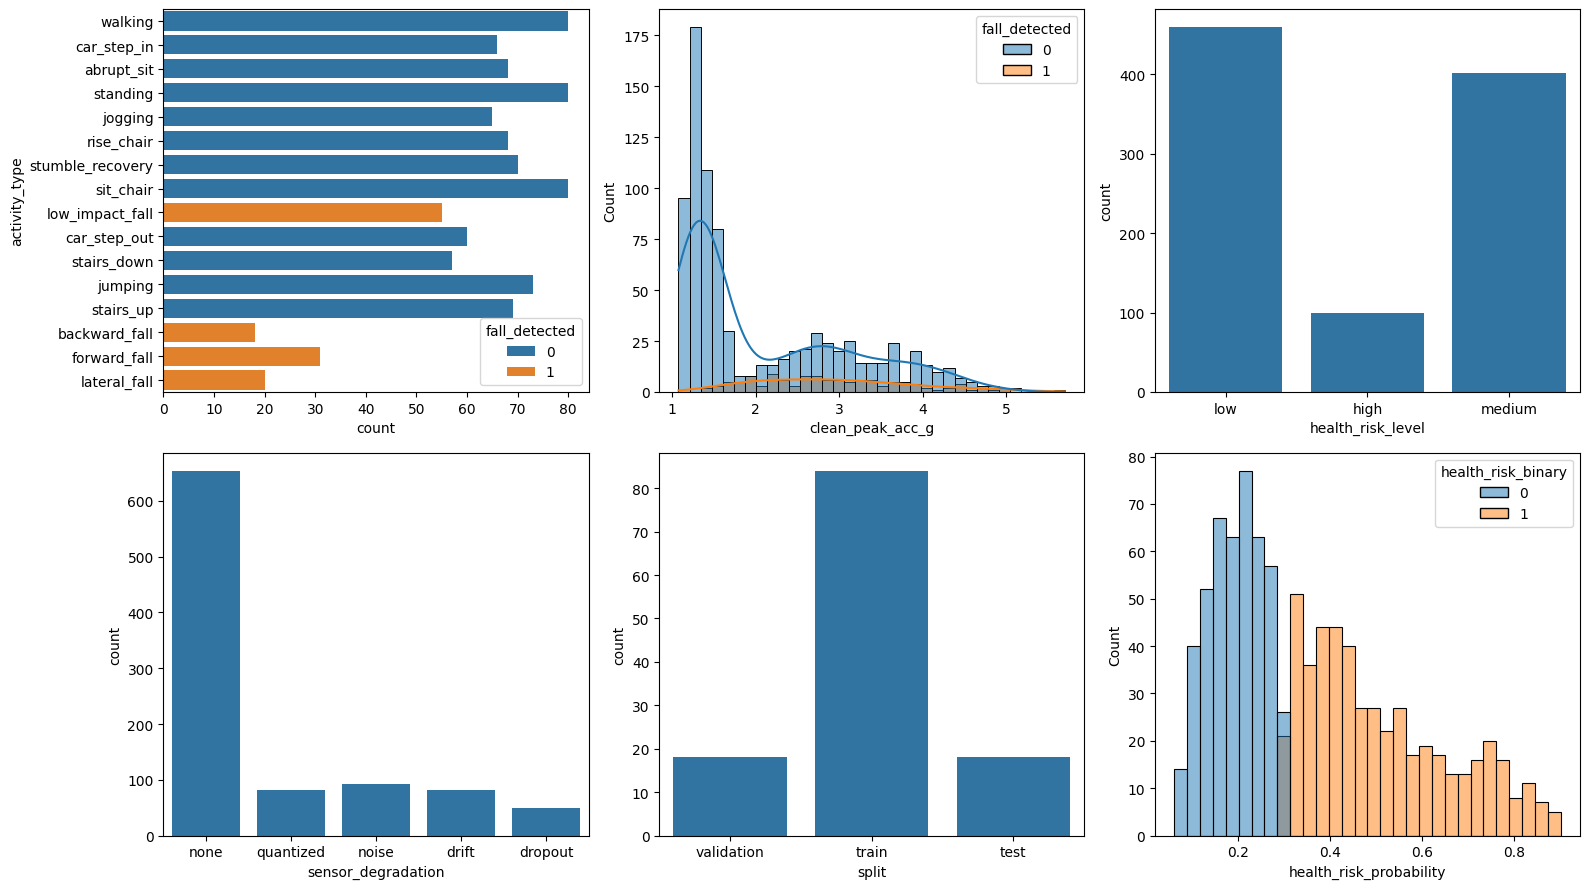

fall_detected,0,1
activity_type,,
abrupt_sit,68,0
backward_fall,0,18
car_step_in,66,0
car_step_out,60,0
forward_fall,0,31
jogging,65,0
jumping,73,0
lateral_fall,0,20
low_impact_fall,0,55


health_risk_level,high,low,medium
health_condition,,,
borderline_fever,0.070,0.098,0.832
borderline_hypoxia,0.581,0.000,0.419
hypertension_episode,0.011,0.529,0.460
hypotension_episode,0.013,0.261,0.726
normal,0.000,0.941,0.059


,0.05,0.25,0.50,0.75,0.95
fall_detected,,,,,
0,2.087722,2.605050,3.075055,3.697945,4.395224
1,1.649235,2.195603,2.847835,3.603638,4.672540


,n_falls,n_hard_negative_adls,fall_peak_median_g,hard_adl_peak_median_g,central_90pct_overlap_low_g,central_90pct_overlap_high_g,central_90pct_ranges_overlap,wasserstein_peak_g
0,124,337,2.847835,3.075055,2.087722,4.395224,True,0.277445


In [20]:
# CELL 15 - Distribution, label balance, and fall/hard-negative overlap audit
fig,axes=plt.subplots(2,3,figsize=(16,9))
sns.countplot(data=events_df,y='activity_type',hue='fall_detected',ax=axes[0,0])
sns.histplot(data=events_df,x='clean_peak_acc_g',hue='fall_detected',bins=35,kde=True,ax=axes[0,1])
sns.countplot(data=events_df,x='health_risk_level',ax=axes[0,2])
sns.countplot(data=events_df,x='sensor_degradation',ax=axes[1,0])
sns.countplot(data=subjects_df,x='split',ax=axes[1,1])
sns.histplot(data=events_df,x='health_risk_probability',hue='health_risk_binary',bins=30,ax=axes[1,2])
plt.tight_layout(); plt.show()
display(pd.crosstab(events_df.activity_type,events_df.fall_detected))
display(pd.crosstab(events_df.health_condition,events_df.health_risk_level,normalize='index').round(3))

overlap_base=events_df[(events_df.fall_detected==1)|(events_df.hard_negative_adl==1)].copy()
q=overlap_base.groupby('fall_detected').clean_peak_acc_g.quantile([.05,.25,.5,.75,.95]).unstack()
fall_peak=overlap_base.loc[overlap_base.fall_detected==1,'clean_peak_acc_g']
hard_peak=overlap_base.loc[overlap_base.fall_detected==0,'clean_peak_acc_g']
overlap_low=max(fall_peak.quantile(.05),hard_peak.quantile(.05)); overlap_high=min(fall_peak.quantile(.95),hard_peak.quantile(.95))
fall_adl_overlap_df=pd.DataFrame([{
    'n_falls':len(fall_peak),'n_hard_negative_adls':len(hard_peak),
    'fall_peak_median_g':fall_peak.median(),'hard_adl_peak_median_g':hard_peak.median(),
    'central_90pct_overlap_low_g':overlap_low,'central_90pct_overlap_high_g':overlap_high,
    'central_90pct_ranges_overlap':bool(overlap_low<overlap_high),
    'wasserstein_peak_g':wasserstein_distance(fall_peak,hard_peak)}])
display(q); display(fall_adl_overlap_df)


## 7. Parent-versus-new-synthetic comparison and optional external-real validation

The simulated parent dataset is compared with the new synthetic events after parent deduplication. This is a **base-to-extension similarity audit**, not proof of real-world validity. A genuinely real external CSV may be supplied separately through `EXTERNAL_REAL_CSV_PATH`.

In [21]:
# CELL 16 — Unit-aware matched-granularity parent comparison

comparison_df = pd.DataFrame()
distinguishability_df = pd.DataFrame()
parent_granularity_audit_df = pd.DataFrame()
external_real_comparison_df = pd.DataFrame()


# ============================================================
# UNIT-AUDIT STATUS HELPER
# ============================================================

def get_parent_unit_status(sensor_family):
    if (
        len(parent_sensor_unit_audit_df)
        and {
            "sensor_family",
            "status"
        }.issubset(
            parent_sensor_unit_audit_df.columns
        )
    ):
        matches = parent_sensor_unit_audit_df[
            parent_sensor_unit_audit_df[
                "sensor_family"
            ].eq(sensor_family)
        ]

        if len(matches):
            return str(
                matches["status"].iloc[0]
            )

    return "not_audited"


# ============================================================
# SELECT ONE INDEPENDENT SYNTHETIC SAMPLE PER EVENT
# ============================================================

def one_random_sample_per_event(
    dataframe,
    seed=SEED
):
    return (
        dataframe
        .groupby(
            "event_id",
            group_keys=False
        )
        .sample(
            n=1,
            random_state=seed
        )
        .reset_index(drop=True)
    )


# ============================================================
# MATCHED-GRANULARITY COMPARISON
# ============================================================

def compare_reference_rows_to_synthetic_samples(
    reference_df,
    reference_kind
):
    # Physiological features and verified acceleration
    # are eligible for comparison.
    candidate_features = [
        "heart_rate_bpm",
        "spo2_pct",
        "temperature_c",
        "hrv_ms",
        "acc_magnitude_g"
    ]

    gyroscope_status = get_parent_unit_status(
        "gyroscope"
    )

    verified_gyroscope_statuses = {
        "documented_dps_used_without_conversion",
        "documented_rad_s_converted_to_dps",
        "documented_raw_counts_converted_to_dps"
    }

    # Parent gyroscope is included only after explicit
    # documentary confirmation and conversion.
    if gyroscope_status in verified_gyroscope_statuses:
        candidate_features.append(
            "gyro_magnitude_dps"
        )

    common_features = []

    for feature in candidate_features:
        if (
            feature in reference_df.columns
            and feature in synthetic_df.columns
        ):
            n_reference = (
                pd.to_numeric(
                    reference_df[feature],
                    errors="coerce"
                )
                .notna()
                .sum()
            )

            n_synthetic = (
                pd.to_numeric(
                    synthetic_df[feature],
                    errors="coerce"
                )
                .notna()
                .sum()
            )

            if (
                n_reference >= 2
                and n_synthetic >= 2
            ):
                common_features.append(feature)

    if len(common_features) < 2:
        return (
            pd.DataFrame(),
            pd.DataFrame(),
            pd.DataFrame()
        )

    reference_values = (
        reference_df[common_features]
        .apply(
            pd.to_numeric,
            errors="coerce"
        )
        .dropna(how="all")
        .drop_duplicates()
    )

    synthetic_values = (
        one_random_sample_per_event(
            synthetic_df[
                ["event_id"]
                + common_features
            ]
        )[common_features]
        .apply(
            pd.to_numeric,
            errors="coerce"
        )
        .dropna(how="all")
    )

    matched_n = min(
        len(reference_values),
        len(synthetic_values)
    )

    reference_values = (
        reference_values
        .sample(
            matched_n,
            random_state=SEED
        )
    )

    synthetic_values = (
        synthetic_values
        .sample(
            matched_n,
            random_state=SEED
        )
    )

    acceleration_status = (
        get_parent_unit_status(
            "accelerometer"
        )
    )

    unit_status = {
        "acc_magnitude_g": (
            acceleration_status
        ),
        "gyro_magnitude_dps": (
            gyroscope_status
        )
    }

    comparison_rows = []

    for feature in common_features:
        reference_feature = (
            reference_values[feature]
            .dropna()
            .to_numpy()
        )

        synthetic_feature = (
            synthetic_values[feature]
            .dropna()
            .to_numpy()
        )

        if (
            len(reference_feature) < 2
            or len(synthetic_feature) < 2
        ):
            continue

        lower = min(
            reference_feature.min(),
            synthetic_feature.min()
        )

        upper = max(
            reference_feature.max(),
            synthetic_feature.max()
        )

        if upper <= lower:
            upper = lower + 1e-6

        bins = np.linspace(
            lower,
            upper,
            31
        )

        reference_histogram, _ = (
            np.histogram(
                reference_feature,
                bins=bins,
                density=True
            )
        )

        synthetic_histogram, _ = (
            np.histogram(
                synthetic_feature,
                bins=bins,
                density=True
            )
        )

        ks_result = ks_2samp(
            reference_feature,
            synthetic_feature
        )

        comparison_rows.append({
            "reference_kind": reference_kind,
            "granularity": (
                "independent_rows_vs_"
                "one_sample_per_event"
            ),
            "feature": feature,
            "parent_unit_status": (
                unit_status.get(
                    feature,
                    "not_applicable"
                )
            ),
            "n_reference": len(
                reference_feature
            ),
            "n_synthetic": len(
                synthetic_feature
            ),
            "wasserstein": (
                wasserstein_distance(
                    reference_feature,
                    synthetic_feature
                )
            ),
            "ks_stat": ks_result.statistic,
            "ks_p": ks_result.pvalue,
            "jensen_shannon": (
                jensenshannon(
                    reference_histogram + 1e-12,
                    synthetic_histogram + 1e-12
                )
            )
        })

    comparison_result = pd.DataFrame(
        comparison_rows
    )

    # --------------------------------------------------------
    # Parent-versus-synthetic distinguishability
    # --------------------------------------------------------

    combined = pd.concat(
        [
            reference_values.assign(
                is_new_synthetic=0
            ),
            synthetic_values.assign(
                is_new_synthetic=1
            )
        ],
        ignore_index=True
    )

    (
        X_train,
        X_test,
        y_train,
        y_test
    ) = train_test_split(
        combined[common_features],
        combined["is_new_synthetic"],
        test_size=0.30,
        stratify=combined[
            "is_new_synthetic"
        ],
        random_state=SEED
    )

    distinguishability_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            LogisticRegression(
                max_iter=2000,
                random_state=SEED
            )
        )
    ])

    distinguishability_pipeline.fit(
        X_train,
        y_train
    )

    synthetic_probability = (
        distinguishability_pipeline
        .predict_proba(X_test)[:, 1]
    )

    distinguishability_result = (
        pd.DataFrame([{
            "reference_kind": reference_kind,
            "granularity": (
                "matched_independent_rows"
            ),
            "n_per_source": matched_n,
            "features_used": ", ".join(
                common_features
            ),
            "accuracy": accuracy_score(
                y_test,
                synthetic_probability >= 0.5
            ),
            "roc_auc": roc_auc_score(
                y_test,
                synthetic_probability
            ),
            "average_precision": (
                average_precision_score(
                    y_test,
                    synthetic_probability
                )
            ),
            "log_loss": log_loss(
                y_test,
                synthetic_probability,
                labels=[0, 1]
            )
        }])
    )

    # --------------------------------------------------------
    # Granularity and unit audit
    # --------------------------------------------------------

    parent_gyroscope_comparison = (
        "included_after_documented_unit_confirmation"
        if "gyro_magnitude_dps"
        in common_features
        else "excluded_unit_not_documented"
    )

    granularity_audit = pd.DataFrame([{
        "reference_kind": reference_kind,
        "parent_unit": "one source row",
        "synthetic_unit": (
            "one randomly selected sample "
            "from each independent event"
        ),
        "sensor_units_audited": True,
        "parent_gyroscope_comparison": (
            parent_gyroscope_comparison
        ),
        "event_level_parent_comparison_performed": (
            False
        ),
        "reason": (
            "Parent file has no verified event "
            "grouping compatible with synthetic events"
        )
    }])

    return (
        comparison_result,
        distinguishability_result,
        granularity_audit
    )


# ============================================================
# RUN THE COMPARISON
# ============================================================

if base_unique_df is not None:
    (
        comparison_df,
        distinguishability_df,
        parent_granularity_audit_df
    ) = compare_reference_rows_to_synthetic_samples(
        base_unique_df,
        "simulated_parent_dataset"
    )

    print("Parent sensor-unit audit:")
    display(parent_sensor_unit_audit_df)

    print("Parent comparison granularity audit:")
    display(parent_granularity_audit_df)

    print("Matched parent-versus-synthetic comparison:")
    display(comparison_df)

    print("Parent-versus-synthetic distinguishability:")
    display(distinguishability_df)

    compared_features = (
        set(comparison_df["feature"])
        if len(comparison_df)
        else set()
    )

    gyroscope_status = get_parent_unit_status(
        "gyroscope"
    )

    if (
        gyroscope_status
        == "excluded_from_physical_comparison"
    ):
        assert (
            "gyro_magnitude_dps"
            not in compared_features
        )

        print(
            "PASS: Parent gyroscope was excluded "
            "because its physical unit could not "
            "be verified."
        )

    elif (
        "gyro_magnitude_dps"
        in compared_features
    ):
        print(
            "Parent gyroscope was included after "
            "documentary unit confirmation:",
            gyroscope_status
        )

    else:
        print(
            "Parent gyroscope was not included. "
            "Current status:",
            gyroscope_status
        )

    if (
        len(distinguishability_df)
        and distinguishability_df[
            "roc_auc"
        ].iloc[0] > 0.90
    ):
        print(
            "WARNING: Parent and synthetic rows "
            "remain readily distinguishable after "
            "verified unit harmonization."
        )

else:
    print(
        "Parent dataset unavailable: "
        "matched-granularity comparison skipped."
    )


print(
    "Important: Similarity to the simulated "
    "parent is not real-world validation."
)

Parent dataset unavailable: matched-granularity comparison skipped.
Important: Similarity to the simulated parent is not real-world validation.


## 8. Leakage-safe event-level modelling

Models use event summaries, not individual high-frequency samples. Subjects never cross train, validation, and test partitions.

In [22]:
# CELL 17 - Event feature table
signal_cols=['acc_x_g','acc_y_g','acc_z_g','acc_magnitude_g','gyro_x_dps','gyro_y_dps','gyro_z_dps',
             'gyro_magnitude_dps','heart_rate_bpm','spo2_pct','temperature_c','hrv_ms',
             'respiratory_rate_bpm','systolic_bp_mmhg','diastolic_bp_mmhg']

agg=synthetic_df.groupby('event_id')[signal_cols].agg(['mean','std','min','max','median'])
agg.columns=[f'{a}_{b}' for a,b in agg.columns]
event_features=events_df.merge(agg.reset_index(),on='event_id',how='left').merge(
    subjects_df[['subject_id','age','sex','diabetes','hypertension','copd','parkinsons','frailty','device_type','placement']],
    on='subject_id',how='left'
)
event_features['age_band']=pd.cut(event_features.age,[64,74,84,100],labels=['65-74','75-84','85+'])
print(event_features.shape)
display(event_features.head())

(960, 107)


,subject_id,event_id,split,sampling_hz,sensor_profile,activity_type,health_condition,sensor_degradation,is_challenge,hard_negative_adl,...,age,sex,diabetes,hypertension,copd,parkinsons,frailty,device_type,placement,age_band
0,S0000,S0000_E000,validation,100,UPFall_Waist_100Hz,walking,normal,none,0,0,...,66,Female,0,0,0,0,0,waist_imu,waist,65-74
1,S0000,S0000_E001,validation,100,UPFall_Waist_100Hz,car_step_in,borderline_hypoxia,none,1,1,...,66,Female,0,0,0,0,0,waist_imu,waist,65-74
2,S0000,S0000_E002,validation,100,UPFall_Waist_100Hz,abrupt_sit,normal,none,1,1,...,66,Female,0,0,0,0,0,waist_imu,waist,65-74
3,S0000,S0000_E003,validation,100,UPFall_Waist_100Hz,standing,borderline_fever,none,1,0,...,66,Female,0,0,0,0,0,waist_imu,waist,65-74
4,S0000,S0000_E004,validation,100,UPFall_Waist_100Hz,jogging,normal,quantized,1,0,...,66,Female,0,0,0,0,0,waist_imu,waist,65-74


In [23]:
# CELL 18 - Task-specific features and complete probabilistic metrics
metadata_exclude={'event_id','subject_id','split','activity_type','health_condition','joint_state','health_risk_level',
                  'health_risk_probability','health_risk_binary','health_outcome_observed','fall_detected',
                  'sensor_degradation','is_challenge','hard_negative_adl','fall_severity','clean_peak_acc_g','n_samples',
                  'parent_article_doi','parent_dataset_doi','parent_snapshot_sha256'}
all_candidate_features=[c for c in event_features.columns if c not in metadata_exclude]
FALL_FEATURES=[c for c in all_candidate_features if c.startswith(('acc_','gyro_'))]
RISK_FEATURES=[c for c in all_candidate_features if c.startswith(('heart_rate_','spo2_','temperature_','hrv_',
               'respiratory_rate_','systolic_bp_','diastolic_bp_')) or c in ['age','sex','diabetes','hypertension','copd','parkinsons','frailty']]
TASK_FEATURES={'fall':FALL_FEATURES,'health_risk':RISK_FEATURES}

MODELS={
    'LogisticRegression':LogisticRegression(max_iter=3000,class_weight='balanced',random_state=SEED),
    'RandomForest':RandomForestClassifier(n_estimators=350,min_samples_leaf=3,class_weight='balanced',n_jobs=-1,random_state=SEED)}

def build_pipeline(features,estimator):
    num=[c for c in features if pd.api.types.is_numeric_dtype(event_features[c])]; cat=[c for c in features if c not in num]
    steps=[]
    if num: steps.append(('num',Pipeline([('imp',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num))
    if cat: steps.append(('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),
                                         ('oh',OneHotEncoder(handle_unknown='ignore'))]),cat))
    return Pipeline([('prep',ColumnTransformer(steps)),('model',clone(estimator))])

def expected_calibration_error(y,p,n_bins=10):
    y=np.asarray(y); p=np.asarray(p); edges=np.linspace(0,1,n_bins+1); ece=0.0
    for lo,hi in zip(edges[:-1],edges[1:]):
        mask=(p>=lo)&(p<(hi if hi<1 else hi+1e-12))
        if mask.any(): ece += mask.mean()*abs(y[mask].mean()-p[mask].mean())
    return float(ece)

def binary_metrics(y,p,threshold=.5):
    y=np.asarray(y,dtype=int); p=np.clip(np.asarray(p,dtype=float),1e-7,1-1e-7); pred=(p>=threshold).astype(int)
    both=len(np.unique(y))==2; cm=confusion_matrix(y,pred,labels=[0,1]).ravel().tolist()
    return {'prevalence':float(y.mean()),'accuracy':accuracy_score(y,pred),
            'balanced_accuracy':balanced_accuracy_score(y,pred) if both else np.nan,
            'precision':precision_score(y,pred,zero_division=0),'recall':recall_score(y,pred,zero_division=0),
            'f1':f1_score(y,pred,zero_division=0),'roc_auc':roc_auc_score(y,p) if both else np.nan,
            'pr_auc':average_precision_score(y,p) if both else np.nan,
            'log_loss':log_loss(y,p,labels=[0,1]),'brier':brier_score_loss(y,p),
            'ece':expected_calibration_error(y,p),'tn_fp_fn_tp':cm}


In [24]:
# CELL 19 - Subject-separated evaluation with one unique test prediction per event
train=event_features[event_features.split=='train'].copy()
validation=event_features[event_features.split=='validation'].copy()
test=event_features[event_features.split=='test'].copy()
evaluation_rows=[]; fitted_models={}; test_prediction_frames=[]

for task,target in {'fall':'fall_detected','health_risk':'health_risk_binary'}.items():
    features=TASK_FEATURES[task]
    for model_name,estimator in MODELS.items():
        pipe=build_pipeline(features,estimator)
        pipe.fit(train[features],train[target])
        fitted_models[(task,model_name)]=pipe

        subsets={'validation_all':validation,'test_all':test,'test_clean':test[test.is_challenge==0],
                 'test_challenge':test[test.is_challenge==1]}
        if task=='fall': subsets['test_hard_negative_adl']=test[test.hard_negative_adl==1]
        for subset_name,subset in subsets.items():
            if len(subset)==0: continue
            prob=pipe.predict_proba(subset[features])[:,1]
            evaluation_rows.append({'task':task,'model':model_name,'subset':subset_name,'n':len(subset),
                                    **binary_metrics(subset[target].to_numpy(),prob)})

        # Store exactly one prediction for every independent held-out test event.
        test_probability=pipe.predict_proba(test[features])[:,1]
        pred_df=test[['subject_id','event_id','sex','age_band','sensor_profile','sensor_degradation',
                      'is_challenge','hard_negative_adl',target]].copy()
        pred_df['task']=task; pred_df['model']=model_name; pred_df['probability']=test_probability
        test_prediction_frames.append(pred_df.rename(columns={target:'y_true'}))

evaluation_df=pd.DataFrame(evaluation_rows)
predictions_df=pd.concat(test_prediction_frames,ignore_index=True)
prediction_key=['task','model','event_id']
duplicate_prediction_rows=int(predictions_df.duplicated(prediction_key).sum())
prediction_integrity_df=pd.DataFrame([{
    'prediction_scope':'held_out_test_only','rows':len(predictions_df),
    'unique_task_model_event_keys':predictions_df[prediction_key].drop_duplicates().shape[0],
    'duplicate_task_model_event_rows':duplicate_prediction_rows,
    'expected_rows':int(len(test)*len(MODELS)*2)
}])
display(evaluation_df)
display(prediction_integrity_df)
assert duplicate_prediction_rows==0
assert len(predictions_df)==len(test)*len(MODELS)*2

# Continuous latent-risk recovery is evaluated separately from binary risk-state classification.
risk_regression_rows=[]
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
for name,estimator in {'Ridge':Ridge(alpha=1.0),'RandomForestRegressor':RandomForestRegressor(
        n_estimators=300,min_samples_leaf=3,n_jobs=-1,random_state=SEED)}.items():
    pipe=build_pipeline(RISK_FEATURES,estimator); pipe.fit(train[RISK_FEATURES],train.health_risk_probability)
    pred=np.clip(pipe.predict(test[RISK_FEATURES]),0,1)
    risk_regression_rows.append({'model':name,'n':len(test),'mae':mean_absolute_error(test.health_risk_probability,pred),
                                 'rmse':mean_squared_error(test.health_risk_probability,pred)**.5,
                                 'r2':r2_score(test.health_risk_probability,pred)})
risk_regression_df=pd.DataFrame(risk_regression_rows); display(risk_regression_df)


,task,model,subset,n,prevalence,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,log_loss,brier,ece,tn_fp_fn_tp
0,fall,LogisticRegression,validation_all,144,0.131944,0.951389,0.905053,0.800000,0.842105,0.820513,0.973895,0.904291,0.132483,0.035016,0.025417,"[121, 4, 3, 16]"
1,fall,LogisticRegression,test_all,144,0.152778,0.986111,0.991803,0.916667,1.000000,0.956522,0.998510,0.991982,0.035748,0.010178,0.019255,"[120, 2, 0, 22]"
2,fall,LogisticRegression,test_clean,12,0.000000,1.000000,NaN,0.000000,0.000000,0.000000,NaN,NaN,0.002590,0.000009,0.002585,"[12, 0, 0, 0]"
3,fall,LogisticRegression,test_challenge,132,0.166667,0.984848,0.990909,0.916667,1.000000,0.956522,0.998347,0.991982,0.038762,0.011103,0.020771,"[108, 2, 0, 22]"
4,fall,LogisticRegression,test_hard_negative_adl,49,0.000000,0.959184,NaN,0.000000,0.000000,0.000000,NaN,NaN,0.078863,0.025156,0.046728,"[47, 2, 0, 0]"
5,fall,RandomForest,validation_all,144,0.131944,0.965278,0.935368,0.850000,0.894737,0.871795,0.980211,0.917028,0.122294,0.033901,0.029378,"[122, 3, 2, 17]"
6,fall,RandomForest,test_all,144,0.152778,0.986111,0.991803,0.916667,1.000000,0.956522,0.999627,0.998024,0.058066,0.012999,0.037210,"[120, 2, 0, 22]"
7,fall,RandomForest,test_clean,12,0.000000,1.000000,NaN,0.000000,0.000000,0.000000,NaN,NaN,0.001673,0.000011,0.001667,"[12, 0, 0, 0]"
8,fall,RandomForest,test_challenge,132,0.166667,0.984848,0.990909,0.916667,1.000000,0.956522,0.999587,0.998024,0.063193,0.014180,0.040441,"[108, 2, 0, 22]"
9,fall,RandomForest,test_hard_negative_adl,49,0.000000,0.959184,NaN,0.000000,0.000000,0.000000,NaN,NaN,0.081377,0.020249,0.065879,"[47, 2, 0, 0]"


,prediction_scope,rows,unique_task_model_event_keys,duplicate_task_model_event_rows,expected_rows
0,held_out_test_only,576,576,0,576


,model,n,mae,rmse,r2
0,Ridge,144,0.144055,0.175106,0.150362
1,RandomForestRegressor,144,0.114540,0.141414,0.445866


In [25]:
# CELL 20 - Subject-grouped cross-validation and paired tests
cv_rows=[]; trainval=event_features[event_features.split.isin(['train','validation'])].copy()
gkf=GroupKFold(n_splits=min(5,trainval.subject_id.nunique()))
for task,target in {'fall':'fall_detected','health_risk':'health_risk_binary'}.items():
    features=TASK_FEATURES[task]
    for fold,(tr,va) in enumerate(gkf.split(trainval,trainval[target],groups=trainval.subject_id),1):
        for model_name,estimator in MODELS.items():
            pipe=build_pipeline(features,estimator); pipe.fit(trainval.iloc[tr][features],trainval.iloc[tr][target])
            p=pipe.predict_proba(trainval.iloc[va][features])[:,1]
            cv_rows.append({'task':task,'fold':fold,'model':model_name,
                            **binary_metrics(trainval.iloc[va][target].to_numpy(),p)})
cv_results_df=pd.DataFrame(cv_rows)
display(cv_results_df.groupby(['task','model'])[['f1','roc_auc','pr_auc','log_loss','brier','ece']].agg(['mean','std']))
test_rows=[]
for task in cv_results_df.task.unique():
    for metric in ['f1','pr_auc','log_loss']:
        pivot=cv_results_df[cv_results_df.task==task].pivot(index='fold',columns='model',values=metric)
        if pivot.shape[1]==2:
            a,b=pivot.columns
            try: stat,p=wilcoxon(pivot[a],pivot[b])
            except ValueError: stat,p=np.nan,np.nan
            test_rows.append({'task':task,'metric':metric,'model_a':a,'model_b':b,'wilcoxon_stat':stat,'p_value':p})
statistical_tests_df=pd.DataFrame(test_rows); display(statistical_tests_df)


f1             roc_auc            \
                                    mean       std      mean       std   
task        model                                                        
fall        LogisticRegression  0.860673  0.094873  0.991770  0.008238   
            RandomForest        0.863045  0.069102  0.989147  0.009241   
health_risk LogisticRegression  0.702951  0.068314  0.761865  0.047246   
            RandomForest        0.773931  0.030370  0.818812  0.024417   

                                  pr_auc            log_loss            \
                                    mean       std      mean       std   
task        model                                                        
fall        LogisticRegression  0.963127  0.032427  0.103666  0.071106   
            RandomForest        0.936778  0.049713  0.097845  0.034068   
health_risk LogisticRegression  0.787586  0.059147  0.599789  0.045488   
            RandomForest        0.832543  0.014571  0.528073  0.024695   

                                   brier                 ece            
                                    mean       std      mean       std  
task        model                                                       
fall        LogisticRegression  0.030151  0.022421  0.037507  0.018232  
            RandomForest        0.027728  0.012141  0.045459  0.011841  
health_risk LogisticRegression  0.202962  0.023716  0.115962  0.024255  
            RandomForest        0.176405  0.012184  0.095254  0.022887

,task,metric,model_a,model_b,wilcoxon_stat,p_value
0,fall,f1,LogisticRegression,RandomForest,7.0,1.0000
1,fall,pr_auc,LogisticRegression,RandomForest,1.0,0.1250
2,fall,log_loss,LogisticRegression,RandomForest,7.0,1.0000
3,health_risk,f1,LogisticRegression,RandomForest,0.0,0.0625
4,health_risk,pr_auc,LogisticRegression,RandomForest,3.0,0.3125
5,health_risk,log_loss,LogisticRegression,RandomForest,0.0,0.0625


In [26]:
# CELL 21 - Subject bootstrap CIs from unique held-out test events only
def subject_bootstrap_ci(pred_df,metric,n_boot=300):
    subjects=pred_df.subject_id.unique(); vals=[]
    for _ in range(n_boot):
        sampled=rng.choice(subjects,size=len(subjects),replace=True); parts=[]
        for i,sid in enumerate(sampled):
            x=pred_df[pred_df.subject_id==sid].copy(); x['_boot_subject']=i; parts.append(x)
        b=pd.concat(parts,ignore_index=True); m=binary_metrics(b.y_true.to_numpy(),b.probability.to_numpy())
        if np.isfinite(m[metric]): vals.append(m[metric])
    return np.quantile(vals,[.025,.5,.975]) if vals else [np.nan]*3
ci_rows=[]
for (task,model),g in predictions_df.groupby(['task','model']):
    for metric in ['f1','pr_auc','log_loss']:
        ci=subject_bootstrap_ci(g,metric)
        ci_rows.append({'task':task,'model':model,'metric':metric,'ci_low':ci[0],'median':ci[1],'ci_high':ci[2]})
confidence_intervals_df=pd.DataFrame(ci_rows); display(confidence_intervals_df)


,task,model,metric,ci_low,median,ci_high
0,fall,LogisticRegression,f1,0.896267,0.958333,1.000000
1,fall,LogisticRegression,pr_auc,0.969484,0.993378,1.000000
2,fall,LogisticRegression,log_loss,0.013675,0.034770,0.067514
3,fall,RandomForest,f1,0.890774,0.960000,1.000000
4,fall,RandomForest,pr_auc,0.989899,1.000000,1.000000
5,fall,RandomForest,log_loss,0.039339,0.058501,0.079209
6,health_risk,LogisticRegression,f1,0.594937,0.701941,0.785397
7,health_risk,LogisticRegression,pr_auc,0.683194,0.793156,0.882994
8,health_risk,LogisticRegression,log_loss,0.527332,0.639079,0.763082
9,health_risk,RandomForest,f1,0.626500,0.751480,0.836647


In [27]:
# CELL 22 - Test-only subgroup analysis (one row per event; descriptive only)
fairness_rows=[]
for (task,model),g0 in predictions_df.groupby(['task','model']):
    for attr in ['sex','age_band']:
        for group,g in g0.groupby(attr,observed=True):
            m=binary_metrics(g.y_true.to_numpy(),g.probability.to_numpy())
            fairness_rows.append({'task':task,'model':model,'attribute':attr,'group':str(group),'n':len(g),
                                  'f1':m['f1'],'recall':m['recall'],'false_positive_rate':m['tn_fp_fn_tp'][1]/max(1,sum(m['tn_fp_fn_tp'][:2]))})
fairness_df=pd.DataFrame(fairness_rows)
display(fairness_df)

fairness_gap_df=(fairness_df.groupby(['task','model','attribute'])[['f1','recall','false_positive_rate']]
                 .agg(lambda s: s.max()-s.min()).reset_index())
fairness_gap_df= fairness_gap_df.rename(columns={'f1':'f1_gap','recall':'recall_gap','false_positive_rate':'fpr_gap'})
display(fairness_gap_df)

,task,model,attribute,group,n,f1,recall,false_positive_rate
0,fall,LogisticRegression,sex,Female,56,0.956522,1.000000,0.022222
1,fall,LogisticRegression,sex,Male,88,0.956522,1.000000,0.012987
2,fall,LogisticRegression,age_band,65-74,32,0.857143,1.000000,0.034483
3,fall,LogisticRegression,age_band,75-84,24,0.888889,1.000000,0.050000
4,fall,LogisticRegression,age_band,85+,88,1.000000,1.000000,0.000000
5,fall,RandomForest,sex,Female,56,1.000000,1.000000,0.000000
6,fall,RandomForest,sex,Male,88,0.916667,1.000000,0.025974
7,fall,RandomForest,age_band,65-74,32,1.000000,1.000000,0.000000
8,fall,RandomForest,age_band,75-84,24,0.888889,1.000000,0.050000
9,fall,RandomForest,age_band,85+,88,0.967742,1.000000,0.013699


,task,model,attribute,f1_gap,recall_gap,fpr_gap
0,fall,LogisticRegression,age_band,0.142857,0.000000,0.050000
1,fall,LogisticRegression,sex,0.000000,0.000000,0.009235
2,fall,RandomForest,age_band,0.111111,0.000000,0.050000
3,fall,RandomForest,sex,0.083333,0.000000,0.025974
4,health_risk,LogisticRegression,age_band,0.077922,0.336538,0.683284
5,health_risk,LogisticRegression,sex,0.093623,0.095109,0.041667
6,health_risk,RandomForest,age_band,0.423077,0.175439,0.575758
7,health_risk,RandomForest,sex,0.177328,0.027174,0.482143


In [28]:
# CELL 23 - Test-only device/domain-shift and degradation analysis
domain_rows=[]
for (task,model),g0 in predictions_df.groupby(['task','model']):
    for attr in ['sensor_profile','sensor_degradation']:
        for group,g in g0.groupby(attr):
            m=binary_metrics(g.y_true.to_numpy(),g.probability.to_numpy())
            domain_rows.append({'task':task,'model':model,'domain_variable':attr,'domain':group,'n':len(g),
                                'f1':m['f1'],'balanced_accuracy':m['balanced_accuracy'],'brier':m['brier'],'ece':m['ece']})
domain_shift_df=pd.DataFrame(domain_rows)
display(domain_shift_df.sort_values(['task','model','domain_variable','f1']))

,task,model,domain_variable,domain,n,f1,balanced_accuracy,brier,ece
8,fall,LogisticRegression,sensor_degradation,dropout,8,0.800000,0.916667,0.051943,0.119754
10,fall,LogisticRegression,sensor_degradation,none,91,0.969697,0.993333,0.010924,0.021362
7,fall,LogisticRegression,sensor_degradation,drift,18,1.000000,1.000000,0.000033,0.003528
9,fall,LogisticRegression,sensor_degradation,noise,17,1.000000,1.000000,0.001709,0.015126
11,fall,LogisticRegression,sensor_degradation,quantized,10,1.000000,1.000000,0.002639,0.019496
0,fall,LogisticRegression,sensor_profile,FARSEEING_L5_100Hz,8,0.000000,NaN,0.000058,0.003573
1,fall,LogisticRegression,sensor_profile,FARSEEING_L5_20Hz,8,0.000000,NaN,0.000054,0.004151
4,fall,LogisticRegression,sensor_profile,UPFall_Pocket_100Hz,16,0.857143,0.961538,0.049352,0.050108
6,fall,LogisticRegression,sensor_profile,UPFall_Wrist_100Hz,32,0.923077,0.980769,0.018382,0.045941
2,fall,LogisticRegression,sensor_profile,MobiAct_Phone_20Hz,16,1.000000,1.000000,0.000029,0.003384


In [29]:
# CELL 24 - Explainability: permutation importance on held-out subjects
importance_rows=[]
for (task,model_name),pipe in fitted_models.items():
    target={'fall':'fall_detected','health_risk':'health_risk_binary'}[task]; features=TASK_FEATURES[task]
    result=permutation_importance(pipe,test[features],test[target],n_repeats=8,random_state=SEED,
                                  scoring='average_precision',n_jobs=-1)
    for f,m,s in zip(features,result.importances_mean,result.importances_std):
        importance_rows.append({'task':task,'model':model_name,'feature':f,'importance_mean':m,'importance_std':s})
permutation_importance_df=pd.DataFrame(importance_rows)
display(permutation_importance_df.sort_values(['task','model','importance_mean'],ascending=[True,True,False])
        .groupby(['task','model']).head(15))


,task,model,feature,importance_mean,importance_std
10,fall,LogisticRegression,acc_z_g_mean,0.027409,1.371670e-02
4,fall,LogisticRegression,acc_x_g_median,0.022780,3.159422e-03
19,fall,LogisticRegression,acc_magnitude_g_median,0.021780,1.318905e-02
0,fall,LogisticRegression,acc_x_g_mean,0.018923,1.145221e-02
11,fall,LogisticRegression,acc_z_g_std,0.004171,8.185973e-03
12,fall,LogisticRegression,acc_z_g_min,0.003635,5.569350e-03
9,fall,LogisticRegression,acc_y_g_median,0.003527,4.408472e-03
16,fall,LogisticRegression,acc_magnitude_g_std,0.002921,5.394250e-03
2,fall,LogisticRegression,acc_x_g_min,0.001687,2.696609e-03
39,fall,LogisticRegression,gyro_magnitude_dps_median,0.001526,4.760245e-03


In [30]:
# CELL 25 - Optional SHAP analysis for the fall Random Forest
# This cell is optional because SHAP can take several minutes.
RUN_SHAP = False
if RUN_SHAP:
    !pip -q install shap
    import shap
    pipe=fitted_models[('fall','RandomForest')]
    X_bg=train[FALL_FEATURES].sample(min(100,len(train)),random_state=SEED)
    X_ex=test[FALL_FEATURES].sample(min(100,len(test)),random_state=SEED)
    # Model-agnostic explanation preserves the complete preprocessing pipeline.
    explainer=shap.Explainer(
        lambda x: pipe.predict_proba(pd.DataFrame(x,columns=FALL_FEATURES))[:,1], X_bg
    )
    shap_values=explainer(X_ex)
    shap.plots.beeswarm(shap_values,max_display=20)
else:
    print('SHAP skipped. Set RUN_SHAP=True when required.')


SHAP skipped. Set RUN_SHAP=True when required.


## 9. Optional external empirical validation with SisFall

Upload the original SisFall dataset ZIP and set `RUN_SISFALL_VALIDATION=True`. This is external validation on real wearable recordings, but the fall protocol is mainly staged. Results are divided into:

- overall staged fall-versus-ADL transfer performance;
- false-positive rate on ADLs performed by elderly participants (`SE` subjects);
- performance for the exceptional older participant who performed falls, when present.

The synthetic fall models use only IMU summary features so that unavailable synthetic physiology or demographic fields cannot leak into external validation.


In [31]:
# CELL 26 — SisFall configuration and robust parser

from pathlib import Path
import re
import shutil
import zipfile

import numpy as np
import pandas as pd


# ============================================================
# 1. CONFIGURATION
# ============================================================

RUN_SISFALL_VALIDATION = True

# ZIP file or already-extracted SisFall directory
SISFALL_PATH = str(SISFALL_ARCHIVE_PATH)
SISFALL_EXPECTED_SHA256 = "7f0dd1583e39fee0f402a6855976eb12517f7eaecdacce871d5b3421793ad665"
SISFALL_PUBLICATION_RUN_SIZE_BYTES = 232407821
SISFALL_ACCESS_DATE = "2026-08-17"

# SisFall sampling frequency
SISFALL_FS = 200

# Use the same window duration employed by the synthetic dataset
SISFALL_WINDOW_SECONDS = float(EVENT_DURATION_SECONDS)
SISFALL_STRIDE_SECONDS = SISFALL_WINDOW_SECONDS / 2.0


# ============================================================
# 2. RESOLVE AND EXTRACT SISFALL DATASET
# ============================================================

def resolve_sisfall_root(path):
    """
    Locate the SisFall dataset.

    If the configured path does not exist, request a file upload.
    If the supplied path is a ZIP archive, extract it safely.
    If it is already a directory, return it unchanged.
    """

    path = Path(path)

    if not path.exists():
        try:
            from google.colab import files
        except ImportError as exc:
            raise FileNotFoundError(
                f"SisFall dataset was not found at: {path}"
            ) from exc

        print("Upload the original SisFall ZIP file now.")
        uploaded = files.upload()

        if not uploaded:
            raise FileNotFoundError("No SisFall file was uploaded.")

        uploaded_name = next(iter(uploaded))
        path = Path("/content") / uploaded_name

    if path.is_dir():
        print(f"Using extracted SisFall directory: {path}")
        return path

    if not path.is_file():
        raise FileNotFoundError(f"Invalid SisFall path: {path}")

    if not zipfile.is_zipfile(path):
        raise ValueError(
            f"The supplied SisFall file is not a valid ZIP archive: {path}"
        )

    extraction_root = Path("/content/sisfall_external_validation")

    if extraction_root.exists():
        shutil.rmtree(extraction_root)

    extraction_root.mkdir(parents=True, exist_ok=True)
    extraction_root_resolved = extraction_root.resolve()

    extracted_files = 0
    skipped_metadata = 0

    with zipfile.ZipFile(path, "r") as archive:
        for member in archive.infolist():

            member_path = Path(member.filename)

            # Skip directories and common macOS metadata files
            if member.is_dir():
                continue

            if (
                "__MACOSX" in member_path.parts
                or member_path.name.startswith("._")
                or member_path.name == ".DS_Store"
            ):
                skipped_metadata += 1
                continue

            # Prevent ZIP path-traversal extraction
            destination = (extraction_root / member.filename).resolve()

            try:
                destination.relative_to(extraction_root_resolved)
            except ValueError:
                print(f"Skipped unsafe ZIP member: {member.filename}")
                continue

            destination.parent.mkdir(parents=True, exist_ok=True)

            with archive.open(member, "r") as source:
                with open(destination, "wb") as target:
                    shutil.copyfileobj(source, target)

            extracted_files += 1

    print(f"SisFall ZIP extracted to: {extraction_root}")
    print(f"Files extracted: {extracted_files:,}")
    print(f"Archive metadata files skipped: {skipped_metadata:,}")

    return extraction_root


# ============================================================
# 3. READ ONE SISFALL SENSOR RECORD
# ============================================================

def read_sisfall_record(path):
    """
    Read one SisFall sensor file and convert the first accelerometer
    and gyroscope channels to physical units.

    First three columns:
        ADXL345 accelerometer, expressed in g.

    Next three columns:
        ITG3200 gyroscope, expressed in degrees per second.
    """

    path = Path(path)

    # Skip archive metadata and irrelevant files
    if (
        path.suffix.lower() not in {".txt", ".csv", ".dat"}
        or path.name.startswith("._")
        or "__MACOSX" in path.parts
        or path.name == ".DS_Store"
    ):
        return None

    raw = None
    last_error = None

    # SisFall files should normally be ASCII/UTF-8, but fallback
    # encodings are included for repackaged dataset archives.
    for encoding in ("utf-8-sig", "cp1252", "latin-1"):
        try:
            candidate = pd.read_csv(
                path,
                sep=r"[,;]",
                header=None,
                engine="python",
                encoding=encoding,
                on_bad_lines="skip"
            )

            if candidate is not None and not candidate.empty:
                raw = candidate
                break

        except (
            UnicodeDecodeError,
            pd.errors.ParserError,
            OSError,
            ValueError
        ) as exc:
            last_error = exc

    if raw is None or raw.empty:
        print(
            f"Skipped unreadable SisFall file: {path.name}"
            + (f" | {last_error}" if last_error else "")
        )
        return None

    # Remove empty columns caused by trailing delimiters
    raw = raw.dropna(axis=1, how="all")

    if raw.shape[1] < 6:
        print(
            f"Skipped {path.name}: only {raw.shape[1]} usable columns found."
        )
        return None

    # Retain ADXL345 x/y/z and ITG3200 x/y/z
    numeric = (
        raw.iloc[:, :6]
        .apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna(axis=0, how="any")
        .reset_index(drop=True)
    )

    if numeric.shape[1] < 6 or len(numeric) < 20:
        print(
            f"Skipped {path.name}: insufficient valid sensor samples "
            f"({len(numeric):,})."
        )
        return None

    # Published SisFall conversion scales:
    # ADXL345: ±16 g with a 13-bit output range
    # ITG3200: ±2000 degrees/s with a 16-bit output range
    acceleration_scale = 32.0 / 8192.0
    gyroscope_scale = 4000.0 / 65536.0

    output = pd.DataFrame(
        numeric.iloc[:, :6].to_numpy(dtype=np.float64),
        columns=[
            "acc_x_raw",
            "acc_y_raw",
            "acc_z_raw",
            "gyro_x_raw",
            "gyro_y_raw",
            "gyro_z_raw"
        ]
    )

    output["acc_x_g"] = output["acc_x_raw"] * acceleration_scale
    output["acc_y_g"] = output["acc_y_raw"] * acceleration_scale
    output["acc_z_g"] = output["acc_z_raw"] * acceleration_scale

    output["gyro_x_dps"] = output["gyro_x_raw"] * gyroscope_scale
    output["gyro_y_dps"] = output["gyro_y_raw"] * gyroscope_scale
    output["gyro_z_dps"] = output["gyro_z_raw"] * gyroscope_scale

    output["acc_magnitude_g"] = np.sqrt(
        output["acc_x_g"] ** 2
        + output["acc_y_g"] ** 2
        + output["acc_z_g"] ** 2
    )

    output["gyro_magnitude_dps"] = np.sqrt(
        output["gyro_x_dps"] ** 2
        + output["gyro_y_dps"] ** 2
        + output["gyro_z_dps"] ** 2
    )

    required_columns = [
        "acc_x_g",
        "acc_y_g",
        "acc_z_g",
        "acc_magnitude_g",
        "gyro_x_dps",
        "gyro_y_dps",
        "gyro_z_dps",
        "gyro_magnitude_dps"
    ]

    return output[required_columns].copy()


# ============================================================
# 4. SUMMARIZE ONE IMU WINDOW
# ============================================================

def summarize_imu_window(window):
    """Calculate the same IMU summary features used by the model."""

    sensor_columns = [
        "acc_x_g",
        "acc_y_g",
        "acc_z_g",
        "acc_magnitude_g",
        "gyro_x_dps",
        "gyro_y_dps",
        "gyro_z_dps",
        "gyro_magnitude_dps"
    ]

    row = {}

    for column in sensor_columns:
        values = (
            pd.to_numeric(window[column], errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )

        if values.empty:
            for statistic in ("mean", "std", "min", "max", "median"):
                row[f"{column}_{statistic}"] = np.nan
            continue

        row[f"{column}_mean"] = float(values.mean())
        row[f"{column}_std"] = float(values.std(ddof=1))
        row[f"{column}_min"] = float(values.min())
        row[f"{column}_max"] = float(values.max())
        row[f"{column}_median"] = float(values.median())

    return row


# ============================================================
# 5. CREATE SISFALL WINDOWS
# ============================================================

def load_sisfall_windows(root):
    """
    Find valid SisFall activity files and convert them into
    fixed-duration, overlapping windows.
    """

    root = Path(root)

    if not root.exists():
        raise FileNotFoundError(f"SisFall root directory not found: {root}")

    window_size = max(
        1,
        int(round(SISFALL_FS * SISFALL_WINDOW_SECONDS))
    )

    stride_size = max(
        1,
        int(round(SISFALL_FS * SISFALL_STRIDE_SECONDS))
    )

    # Examples:
    # D01_SA01_R01.txt
    # F01_SE01_R01.txt
    filename_pattern = re.compile(
        r"^(D\d{2}|F\d{2})_((?:SA|SE)\d{2})_R(\d{2})$",
        flags=re.IGNORECASE
    )

    rows = []

    files_examined = 0
    files_recognized = 0
    files_loaded = 0
    files_too_short = 0
    metadata_files_skipped = 0

    for path in sorted(root.rglob("*.txt")):
        files_examined += 1

        # Explicitly reject macOS resource-fork files
        if (
            path.name.startswith("._")
            or "__MACOSX" in path.parts
            or path.name == ".DS_Store"
        ):
            metadata_files_skipped += 1
            continue

        match = filename_pattern.fullmatch(path.stem)

        if match is None:
            continue

        files_recognized += 1

        activity, subject, trial = match.groups()

        activity = activity.upper()
        subject = subject.upper()
        trial = trial.upper()

        record = read_sisfall_record(path)

        if record is None:
            continue

        if len(record) < window_size:
            files_too_short += 1
            continue

        files_loaded += 1

        starts = list(
            range(
                0,
                len(record) - window_size + 1,
                stride_size
            )
        )

        # Defensive fallback; normally unnecessary after the length check
        if not starts:
            starts = [max(0, (len(record) - window_size) // 2)]

        for window_number, start in enumerate(starts):
            stop = start + window_size
            window = record.iloc[start:stop]

            relative_file = path.relative_to(root).as_posix()
            relative_stem = relative_file.rsplit('.', 1)[0]
            unique_event_id = relative_stem.replace('/', '__')
            row = {
                "external_event_id": unique_event_id,
                "external_window_id": (
                    f"{unique_event_id}_W{window_number:03d}"
                ),
                "source_file": relative_file,
                "subject_id": subject,
                "activity_code": activity,
                "trial_number": trial,
                "window_start_sample": int(start),
                "window_end_sample": int(stop),
                "fall_detected": int(activity.startswith("F")),
                "elderly_subject": int(subject.startswith("SE")),
                **summarize_imu_window(window)
            }

            rows.append(row)

    result = pd.DataFrame(rows)

    print("\nSisFall parsing summary")
    print("-" * 35)
    print(f"Text files examined       : {files_examined:,}")
    print(f"Metadata files skipped    : {metadata_files_skipped:,}")
    print(f"Recognized SisFall files  : {files_recognized:,}")
    print(f"Successfully loaded files : {files_loaded:,}")
    print(f"Files shorter than window : {files_too_short:,}")
    unique_events = int(result['external_event_id'].nunique()) if len(result) else 0
    duplicate_event_file_ids = int(
        result[['external_event_id','source_file']].drop_duplicates().duplicated('external_event_id').sum()
    ) if len(result) else 0
    print(f"Generated windows         : {len(result):,}")
    print(f"Unique event identifiers  : {unique_events:,}")
    print(f"Event-ID file collisions  : {duplicate_event_file_ids:,}")
    print(f"Window size               : {window_size:,} samples")
    assert duplicate_event_file_ids == 0
    assert unique_events == files_loaded
    print(f"Window stride             : {stride_size:,} samples")

    if not result.empty:
        print("\nWindow class distribution:")
        print(
            result["fall_detected"]
            .map({0: "ADL", 1: "Fall"})
            .value_counts()
        )

        print("\nSubject-group distribution:")
        print(
            result["elderly_subject"]
            .map({0: "Young adult", 1: "Older adult"})
            .value_counts()
        )

    return result


In [32]:
# CELL 27 - Synthetic-to-SisFall transfer, SE06 protocol, and elderly-ADL alert audit
sisfall_window_df=pd.DataFrame()
sisfall_event_predictions_df=pd.DataFrame()
external_validation_df=pd.DataFrame()
elderly_adl_subject_fpr_df=pd.DataFrame()
sisfall_event_id_audit_df=pd.DataFrame()
sisfall_source_provenance_df=pd.DataFrame()

if RUN_SISFALL_VALIDATION:
    sisfall_root=resolve_sisfall_root(SISFALL_PATH)
    sisfall_input = Path(SISFALL_PATH)
    if sisfall_input.is_file():
        sisfall_size = sisfall_input.stat().st_size
        sisfall_sha256 = hashlib.sha256(sisfall_input.read_bytes()).hexdigest()
    else:
        sisfall_size = SISFALL_PUBLICATION_RUN_SIZE_BYTES
        sisfall_sha256 = SISFALL_EXPECTED_SHA256
    sisfall_source_provenance_df = pd.DataFrame([{
        'dataset':'SisFall', 'article_doi':'10.3390/s17010198',
        'source_file':sisfall_input.name, 'accessed_date':SISFALL_ACCESS_DATE,
        'size_bytes':sisfall_size, 'sha256':sisfall_sha256,
        'expected_size_bytes':SISFALL_PUBLICATION_RUN_SIZE_BYTES,
        'expected_sha256':SISFALL_EXPECTED_SHA256,
        'archive_fingerprint_status':'PASS_EXACT_ARCHIVE' if (sisfall_size == SISFALL_PUBLICATION_RUN_SIZE_BYTES and sisfall_sha256 == SISFALL_EXPECTED_SHA256) else 'FAIL',
        'interpretation':'Measured wearable recordings; falls staged; not clinical validation'
    }])
    sisfall_window_df=load_sisfall_windows(sisfall_root)
    if sisfall_window_df.empty:
        raise ValueError('No SisFall records were recognized. Expected names such as D01_SA01_R01.txt.')
    missing=[c for c in FALL_FEATURES if c not in sisfall_window_df]
    if missing: raise ValueError(f'SisFall adapter is missing required IMU features: {missing}')

    event_file_map=sisfall_window_df[['external_event_id','source_file']].drop_duplicates()
    sisfall_event_id_audit_df=pd.DataFrame([{
        'recognized_event_files':int(len(event_file_map)),
        'unique_external_event_ids':int(event_file_map.external_event_id.nunique()),
        'event_id_file_collisions':int(event_file_map.duplicated('external_event_id').sum())
    }])
    recognized_recordings = int(sisfall_event_id_audit_df.recognized_event_files.iloc[0])
    unique_recordings = int(sisfall_event_id_audit_df.unique_external_event_ids.iloc[0])
    event_id_collisions = int(sisfall_event_id_audit_df.event_id_file_collisions.iloc[0])
    generated_windows = int(len(sisfall_window_df))
    content_validation_pass = (
        recognized_recordings == 4505
        and unique_recordings == 4505
        and event_id_collisions == 0
        and generated_windows == 33823
    )
    sisfall_source_provenance_df['expected_recognized_recordings'] = 4505
    sisfall_source_provenance_df['recognized_recordings'] = recognized_recordings
    sisfall_source_provenance_df['unique_external_event_ids'] = unique_recordings
    sisfall_source_provenance_df['event_id_collisions'] = event_id_collisions
    sisfall_source_provenance_df['expected_windows'] = 33823
    sisfall_source_provenance_df['generated_windows'] = generated_windows
    sisfall_source_provenance_df['content_validation_status'] = 'PASS' if content_validation_pass else 'FAIL'

    display(sisfall_source_provenance_df)
    display(sisfall_event_id_audit_df)
    assert sisfall_source_provenance_df.archive_fingerprint_status.iloc[0] == 'PASS_EXACT_ARCHIVE'
    assert sisfall_source_provenance_df.content_validation_status.iloc[0] == 'PASS'
    print('PASS: exact SisFall ZIP fingerprint verified.')
    print('PASS: all 4,505 expected recordings produced 33,823 windows with zero ID collisions.')

    pred_rows=[]
    for model_name in MODELS:
        pipe=fitted_models[('fall',model_name)]
        p=pipe.predict_proba(sisfall_window_df[FALL_FEATURES])[:,1]
        w=sisfall_window_df[['external_event_id','source_file','subject_id','activity_code',
                             'fall_detected','elderly_subject']].copy()
        w['model']=model_name; w['window_probability']=p; pred_rows.append(w)
    windows_pred=pd.concat(pred_rows,ignore_index=True)

    # Maximum window probability is an alert-oriented event score. Because long
    # recordings produce more windows, report it explicitly as an event-alert audit.
    sisfall_event_predictions_df=(
        windows_pred.groupby(['model','external_event_id','source_file','subject_id','activity_code',
                              'fall_detected','elderly_subject'],as_index=False)
        .window_probability.max().rename(columns={'window_probability':'probability'})
    )

    rows=[]; subject_fpr_rows=[]
    HIGH_ELDERLY_ADL_FPR_THRESHOLD=0.10
    for model_name,g in sisfall_event_predictions_df.groupby('model'):
        rows.append({'dataset':'SisFall','cohort':'all_recordings_staged_falls_and_adls',
                     'interpretation':'Measured waist IMU transfer; falls are staged',
                     'model':model_name,'n':len(g),**binary_metrics(g.fall_detected,g.probability)})

        young=g[g.elderly_subject==0]
        if young.fall_detected.nunique()==2:
            rows.append({'dataset':'SisFall','cohort':'young_adults_staged_falls_and_adls',
                         'interpretation':'Young-adult staged falls and ADLs',
                         'model':model_name,'n':len(young),**binary_metrics(young.fall_detected,young.probability)})

        elderly_adl=g[(g.elderly_subject==1)&(g.fall_detected==0)].copy()
        if len(elderly_adl):
            pred=(elderly_adl.probability>=.5).astype(int)
            fpr=float(pred.mean())
            rows.append({'dataset':'SisFall','cohort':'elderly_adl_false_positive_audit',
                         'interpretation':'Older participants performed ADLs; false-alarm audit only',
                         'model':model_name,'n':len(elderly_adl),'prevalence':0.0,
                         'accuracy':float((pred==0).mean()),'balanced_accuracy':np.nan,
                         'precision':np.nan,'recall':np.nan,'f1':np.nan,'roc_auc':np.nan,'pr_auc':np.nan,
                         'log_loss':log_loss(np.zeros(len(elderly_adl),dtype=int),elderly_adl.probability,labels=[0,1]),
                         'brier':brier_score_loss(np.zeros(len(elderly_adl),dtype=int),elderly_adl.probability),
                         'ece':expected_calibration_error(np.zeros(len(elderly_adl),dtype=int),elderly_adl.probability),
                         'tn_fp_fn_tp':confusion_matrix(np.zeros(len(elderly_adl),dtype=int),pred,labels=[0,1]).ravel().tolist(),
                         'false_positive_rate':fpr,
                         'high_false_positive_warning':bool(fpr>=HIGH_ELDERLY_ADL_FPR_THRESHOLD)})
            for subject,sg in elderly_adl.groupby('subject_id'):
                sp=(sg.probability>=.5).astype(int)
                subject_fpr_rows.append({'dataset':'SisFall','model':model_name,'subject_id':subject,
                                         'n_adl_events':len(sg),'false_positive_events':int(sp.sum()),
                                         'false_positive_rate':float(sp.mean()),
                                         'mean_probability':float(sg.probability.mean()),
                                         'high_false_positive_warning':bool(sp.mean()>=HIGH_ELDERLY_ADL_FPR_THRESHOLD)})

        # Published SisFall protocol: among older participants, only SE06 (age 60,
        # experienced in judo) simulated falls. Do not pool those falls as if they
        # represented all older participants.
        se06=g[g.subject_id.str.upper()=='SE06']
        if len(se06) and se06.fall_detected.nunique()==2:
            rows.append({'dataset':'SisFall','cohort':'SE06_only_staged_falls_and_adls',
                         'interpretation':'Single 60-year-old judo-experienced participant; not general elderly-fall validation',
                         'model':model_name,'n':len(se06),**binary_metrics(se06.fall_detected,se06.probability)})

    external_validation_df=pd.DataFrame(rows)
    elderly_adl_subject_fpr_df=pd.DataFrame(subject_fpr_rows)
    display(external_validation_df)
    print('Elderly-ADL false-positive rate by participant:')
    display(elderly_adl_subject_fpr_df)

    high_rows=external_validation_df[
        (external_validation_df.cohort=='elderly_adl_false_positive_audit') &
        (external_validation_df.false_positive_rate>=HIGH_ELDERLY_ADL_FPR_THRESHOLD)
    ]
    if len(high_rows):
        print('WARNING: elderly-ADL false-positive rate is at least 10% for:')
        for _,row in high_rows.iterrows():
            print(f"  {row['model']}: {100*row['false_positive_rate']:.1f}%")
        print('These models are not deployment-ready at the fixed 0.50 threshold.')

    print('Interpretation: SisFall supports transfer to measured wearable signals, mainly staged falls.')
    print('Only SE06 supplies older-person staged falls; natural real-world elderly-fall validity is not established.')
else:
    print('SisFall validation not run. Set RUN_SISFALL_VALIDATION=True and supply the original ZIP before making an external-validity claim.')


SisFall ZIP extracted to: /content/sisfall_external_validation
Files extracted: 4,700
Archive metadata files skipped: 4,743

SisFall parsing summary
-----------------------------------
Text files examined       : 4,506
Metadata files skipped    : 0
Recognized SisFall files  : 4,505
Successfully loaded files : 4,505
Files shorter than window : 0
Generated windows         : 33,823
Unique event identifiers  : 4,505
Event-ID file collisions  : 0
Window size               : 800 samples
Window stride             : 400 samples

Window class distribution:
fall_detected
ADL     23035
Fall    10788
Name: count, dtype: int64

Subject-group distribution:
elderly_subject
Young adult    25347
Older adult     8476
Name: count, dtype: int64


,dataset,article_doi,source_file,accessed_date,size_bytes,sha256,expected_size_bytes,expected_sha256,archive_fingerprint_status,interpretation,expected_recognized_recordings,recognized_recordings,unique_external_event_ids,event_id_collisions,expected_windows,generated_windows,content_validation_status
0,SisFall,10.3390/s17010198,SisFall_dataset.zip,2026-08-17,232407821,7f0dd1583e39fee0f402a6855976eb12517f7eaecdacce...,232407821,7f0dd1583e39fee0f402a6855976eb12517f7eaecdacce...,PASS_EXACT_ARCHIVE,Measured wearable recordings; falls staged; no...,4505,4505,4505,0,33823,33823,PASS


,recognized_event_files,unique_external_event_ids,event_id_file_collisions
0,4505,4505,0


PASS: exact SisFall ZIP fingerprint verified.
PASS: all 4,505 expected recordings produced 33,823 windows with zero ID collisions.


,dataset,cohort,interpretation,model,n,prevalence,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,log_loss,brier,ece,tn_fp_fn_tp,false_positive_rate,high_false_positive_warning
0,SisFall,all_recordings_staged_falls_and_adls,Measured waist IMU transfer; falls are staged,LogisticRegression,4505,0.399112,0.788679,0.812300,0.669471,0.929366,0.778295,0.866522,0.735109,2.310869,0.200932,0.198077,"[1882, 825, 127, 1671]",NaN,NaN
1,SisFall,young_adults_staged_falls_and_adls,Young-adult staged falls and ADLs,LogisticRegression,3532,0.487826,0.827576,0.830061,0.765491,0.932095,0.840618,0.882409,0.819689,1.858937,0.163644,0.160609,"[1317, 492, 117, 1606]",NaN,NaN
2,SisFall,elderly_adl_false_positive_audit,Older participants performed ADLs; false-alarm...,LogisticRegression,898,0.000000,0.629176,NaN,NaN,NaN,NaN,NaN,NaN,5.891497,0.354419,0.371885,"[565, 333, 0, 0]",0.370824,True
3,SisFall,SE06_only_staged_falls_and_adls,Single 60-year-old judo-experienced participan...,LogisticRegression,154,0.487013,0.701299,0.705485,0.643564,0.866667,0.738636,0.745907,0.669848,3.100287,0.285208,0.287472,"[43, 36, 10, 65]",NaN,NaN
4,SisFall,all_recordings_staged_falls_and_adls,Measured waist IMU transfer; falls are staged,RandomForest,4505,0.399112,0.754717,0.728759,0.736519,0.600111,0.661355,0.851372,0.734640,0.520269,0.170469,0.132027,"[2321, 386, 719, 1079]",NaN,NaN
5,SisFall,young_adults_staged_falls_and_adls,Young-adult staged falls and ADLs,RandomForest,3532,0.487826,0.721687,0.718811,0.778195,0.600696,0.678022,0.839757,0.796684,0.547126,0.183131,0.156565,"[1514, 295, 688, 1035]",NaN,NaN
6,SisFall,elderly_adl_false_positive_audit,Older participants performed ADLs; false-alarm...,RandomForest,898,0.000000,0.898664,NaN,NaN,NaN,NaN,NaN,NaN,0.406055,0.116577,0.309909,"[807, 91, 0, 0]",0.101336,True
7,SisFall,SE06_only_staged_falls_and_adls,Single 60-year-old judo-experienced participan...,RandomForest,154,0.487013,0.720779,0.717384,0.785714,0.586667,0.671756,0.899409,0.892327,0.506556,0.165059,0.245524,"[67, 12, 31, 44]",NaN,NaN


Elderly-ADL false-positive rate by participant:


,dataset,model,subject_id,n_adl_events,false_positive_events,false_positive_rate,mean_probability,high_false_positive_warning
0,SisFall,LogisticRegression,SE01,59,21,0.355932,0.355641,True
1,SisFall,LogisticRegression,SE02,48,24,0.500000,0.509090,True
2,SisFall,LogisticRegression,SE03,59,16,0.271186,0.269917,True
3,SisFall,LogisticRegression,SE04,59,18,0.305085,0.319133,True
4,SisFall,LogisticRegression,SE05,59,17,0.288136,0.299405,True
5,SisFall,LogisticRegression,SE06,79,36,0.455696,0.459205,True
6,SisFall,LogisticRegression,SE07,59,23,0.389831,0.386830,True
7,SisFall,LogisticRegression,SE08,59,14,0.237288,0.224903,True
8,SisFall,LogisticRegression,SE09,59,35,0.593220,0.596175,True
9,SisFall,LogisticRegression,SE10,59,18,0.305085,0.299950,True


  LogisticRegression: 37.1%
  RandomForest: 10.1%
These models are not deployment-ready at the fixed 0.50 threshold.
Interpretation: SisFall supports transfer to measured wearable signals, mainly staged falls.
Only SE06 supplies older-person staged falls; natural real-world elderly-fall validity is not established.


## 9. Export dataset, metadata, validation evidence, and reproducibility manifest

In [33]:
# CELL 28 - Complete dictionaries, release tables, and reproducibility manifest
import platform
from importlib import metadata as importlib_metadata

def schema(description, unit='not_applicable', level='sample', allowed='documented generator domain', missingness='not expected'):
    return {
        'description': description,
        'unit': unit,
        'level': level,
        'allowed_values_or_range': allowed,
        'missingness_definition': missingness,
    }

# Every column of the primary time-series table is explicitly documented.
raw_schema = {
    'subject_id': schema('Synthetic participant identifier; stable across all events for one participant.', level='subject', allowed='S0000–S0119'),
    'event_id': schema('Unique synthetic event identifier composed of subject and event number.', level='event', allowed='S####_E###'),
    'split': schema('Subject-level allocation assigned before event generation.', level='subject', allowed='train, validation, test'),
    'sampling_hz': schema('Sampling frequency determined by the selected sensor profile.', 'Hz', 'event', '20, 100, or 200'),
    'sensor_profile': schema('Named literature-informed device, placement, and sampling profile.', level='subject', allowed='one of seven profiles in sensor_profiles.csv'),
    'device_type': schema('Generic wearable device category associated with the sensor profile.', level='subject', allowed='smartphone, smartwatch, waist_imu, chest_imu'),
    'placement': schema('Body or carried-device location associated with the sensor profile.', level='subject', allowed='waist, wrist, chest, pocket'),
    'activity_type': schema('Generated activity-of-daily-living or fall scenario.', level='event', allowed='scenario library defined in the notebook'),
    'health_condition': schema('Generated physiological condition applied during the event.', level='event', allowed='normal, borderline_fever, borderline_hypoxia, hypertension_episode, hypotension_episode'),
    'sensor_degradation': schema('Deliberate post-generation sensor-quality mode.', level='event', allowed='none, noise, dropout, quantized, drift'),
    'is_challenge': schema('Indicator that an event contains a fall, hard negative, non-normal condition, or sensor degradation.', level='event', allowed='0 or 1'),
    'hard_negative_adl': schema('Indicator for a fall-like activity-of-daily-living event that is labelled non-fall.', level='event', allowed='0 or 1'),
    'fall_severity': schema('Continuous latent fall-severity parameter used by the motion generator.', 'arbitrary latent scale', 'event', '0–1 for falls', 'structurally missing for non-falls'),
    'fall_detected': schema('Binary event-level fall ground truth from the scenario class.', level='event', allowed='0 non-fall; 1 fall'),
    'health_risk_probability': schema('Latent event-level probability produced by the documented risk equation.', 'probability', 'event', '0–1'),
    'health_risk_level': schema('Categorical risk band derived deterministically from health_risk_probability.', level='event', allowed='Low, Moderate, High'),
    'health_risk_binary': schema('Binary elevated-risk benchmark target obtained from the documented probability threshold.', level='event', allowed='0 or 1'),
    'health_outcome_observed': schema('Separate Bernoulli realization from health_risk_probability; not the benchmark target.', level='event', allowed='0 or 1'),
    'joint_state': schema('Combined deterministic health-risk and fall state.', level='event', allowed='four states defined by FIXED_JOINT_STATE'),
    'generation_version': schema('Version of the synthetic generator that produced the record.', level='release', allowed='3.1.0'),
    'parent_article_doi': schema('DOI of the parent Data in Brief article used for dataset lineage.', level='release', allowed=PARENT_ARTICLE_DOI),
    'parent_dataset_doi': schema('DOI of the declared Version-2 parent dataset snapshot.', level='release', allowed=PARENT_DATASET_DOI),
    'parent_snapshot_sha256': schema('SHA-256 fingerprint recorded for the frozen Version-2 parent snapshot.', level='release', allowed=EXPECTED_PARENT_SHA256),
    'motion_reference': schema('Literature source family used to motivate the motion profile.', level='subject', allowed='reference key in sensor_profiles.csv'),
    'physiology_reference': schema('Literature source key used to motivate physiological ranges.', level='release', allowed='Chester_Rudolph_2011'),
    'realism_reference': schema('Literature source key used to motivate real-like versus simulated fall overlap.', level='release', allowed='Casilari_Silva_real_vs_simulated'),
    'sample_index': schema('Zero-based sample number within one event.', 'index', 'sample', '0 to n_samples−1'),
    'time_from_event_start_s': schema('Elapsed time from the beginning of the event.', 's', 'sample', '0 to <4 s'),
    'timestamp_utc': schema('Synthetic UTC timestamp formed from subject day, event offset, and sample time.', 'UTC datetime', 'sample', 'ISO-8601 timestamp'),
    'event_phase': schema('Generator phase assigned to the sample.', level='sample', allowed='pre-event, transition/descent, peak/impact, recovery/post-event'),
    'acc_x_g': schema('Acceleration on the x axis.', 'g', 'sample', 'configured physical range', 'missing only in deliberate dropout intervals'),
    'acc_y_g': schema('Acceleration on the y axis.', 'g', 'sample', 'configured physical range', 'missing only in deliberate dropout intervals'),
    'acc_z_g': schema('Acceleration on the z axis.', 'g', 'sample', 'configured physical range', 'missing only in deliberate dropout intervals'),
    'acc_magnitude_g': schema('Euclidean magnitude of the three acceleration axes.', 'g', 'sample', '0–20', 'missing when dropout makes the component axes missing'),
    'gyro_x_dps': schema('Angular velocity on the x axis.', 'degrees/s', 'sample', 'configured physical range', 'missing only in deliberate dropout intervals'),
    'gyro_y_dps': schema('Angular velocity on the y axis.', 'degrees/s', 'sample', 'configured physical range', 'missing only in deliberate dropout intervals'),
    'gyro_z_dps': schema('Angular velocity on the z axis.', 'degrees/s', 'sample', 'configured physical range', 'missing only in deliberate dropout intervals'),
    'gyro_magnitude_dps': schema('Euclidean magnitude of the three angular-velocity axes.', 'degrees/s', 'sample', '0–2500', 'missing when dropout makes the component axes missing'),
    'heart_rate_bpm': schema('Generated heart rate during the event.', 'beats/min', 'sample', '40–180'),
    'spo2_pct': schema('Generated peripheral oxygen saturation.', '%', 'sample', '75–100'),
    'temperature_c': schema('Generated body temperature.', '°C', 'sample', '34.5–40.5'),
    'hrv_ms': schema('Generated heart-rate-variability measure.', 'ms', 'sample', '3–100'),
    'respiratory_rate_bpm': schema('Generated respiratory rate.', 'breaths/min', 'sample', '6–40'),
    'systolic_bp_mmhg': schema('Generated systolic blood pressure.', 'mmHg', 'sample', '70–220'),
    'diastolic_bp_mmhg': schema('Generated diastolic blood pressure.', 'mmHg', 'sample', '35–140'),
}

subject_schema = {
    'subject_id': raw_schema['subject_id'],
    'split': raw_schema['split'],
    'age': schema('Synthetic participant age.', 'years', 'subject', '65–95'),
    'sex': schema('Synthetic binary sex category used by the generator.', level='subject', allowed='Female or Male'),
    'diabetes': schema('Synthetic diabetes indicator.', level='subject', allowed='0 or 1'),
    'hypertension': schema('Synthetic hypertension indicator.', level='subject', allowed='0 or 1'),
    'copd': schema('Synthetic chronic obstructive pulmonary disease indicator.', level='subject', allowed='0 or 1'),
    'parkinsons': schema('Synthetic Parkinson’s disease indicator.', level='subject', allowed='0 or 1'),
    'frailty': schema('Synthetic frailty indicator.', level='subject', allowed='0 or 1'),
    'sensor_profile': raw_schema['sensor_profile'],
    'device_type': raw_schema['device_type'],
    'placement': raw_schema['placement'],
    'sampling_hz': raw_schema['sampling_hz'],
    'motion_reference': raw_schema['motion_reference'],
    'baseline_heart_rate': schema('Fixed subject-level baseline heart rate used by the event generator.', 'beats/min', 'subject', '52–105'),
    'baseline_spo2': schema('Fixed subject-level baseline peripheral oxygen saturation used by the event generator.', '%', 'subject', '88–100'),
    'baseline_temperature': schema('Fixed subject-level baseline body temperature used by the event generator.', '°C', 'subject', '35.7–37.2'),
    'baseline_hrv': schema('Fixed subject-level baseline heart-rate-variability value used by the event generator.', 'ms', 'subject', '8–65'),
    'baseline_respiratory_rate': schema('Fixed subject-level baseline respiratory rate used by the event generator.', 'breaths/min', 'subject', '9–26'),
    'baseline_systolic_bp': schema('Fixed subject-level baseline systolic blood pressure used by the event generator.', 'mmHg', 'subject', '90–190'),
    'baseline_diastolic_bp': schema('Fixed subject-level baseline diastolic blood pressure used by the event generator.', 'mmHg', 'subject', '50–115'),
}

event_metadata_schema = {
    key: value for key, value in raw_schema.items()
    if key in events_df.columns
}
event_metadata_schema['n_samples'] = schema('Number of sample rows in the event.', 'count', 'event', 'sampling_hz × 4 seconds')
event_metadata_schema['clean_peak_acc_g'] = schema('Peak acceleration magnitude before deliberate sensor degradation.', 'g', 'event', 'non-negative')

statistic_labels = {
    'mean': 'arithmetic mean', 'std': 'sample standard deviation',
    'min': 'minimum', 'max': 'maximum', 'median': 'median',
}
event_feature_schema = dict(event_metadata_schema)
for column in event_features.columns:
    if column in event_feature_schema:
        continue
    matched = False
    for suffix, label in statistic_labels.items():
        token = '_' + suffix
        if column.endswith(token):
            base_column = column[:-len(token)]
            if base_column in raw_schema:
                base = raw_schema[base_column]
                event_feature_schema[column] = schema(
                    f"Event-level {label} of {base['description']}",
                    base['unit'], 'event', 'numeric summary of available samples',
                    'missing only if no usable sample exists for the event',
                )
                matched = True
                break
    if not matched:
        raise AssertionError(f'Undocumented event-feature column: {column}')

prediction_schema = {
    'subject_id': raw_schema['subject_id'], 'event_id': raw_schema['event_id'],
    'sex': subject_schema['sex'], 'age_band': subject_schema['age_band'],
    'sensor_profile': raw_schema['sensor_profile'],
    'sensor_degradation': raw_schema['sensor_degradation'],
    'is_challenge': raw_schema['is_challenge'],
    'hard_negative_adl': raw_schema['hard_negative_adl'],
    'y_true': schema('Observed binary benchmark label for the named task.', level='event', allowed='0 or 1'),
    'task': schema('Prediction task represented by the row.', level='event', allowed='fall or health_risk'),
    'model': schema('Fitted benchmark model that produced the probability.', level='event', allowed='LogisticRegression or RandomForest'),
    'probability': schema('Held-out model probability for y_true=1.', 'probability', 'event', '0–1'),
}

def dictionary_rows(table_name, dataframe, table_schema):
    missing_definitions = sorted(set(dataframe.columns) - set(table_schema))
    extra_definitions = sorted(set(table_schema) - set(dataframe.columns))
    assert not missing_definitions, f'{table_name} has undocumented columns: {missing_definitions}'
    if extra_definitions:
        print(f'Note: unused definitions for {table_name}:', extra_definitions)
    rows = []
    for column in dataframe.columns:
        item = table_schema[column]
        rows.append({
            'table': table_name,
            'column': column,
            'dtype': str(dataframe[column].dtype),
            **item,
            'nullable_in_release': bool(dataframe[column].isna().any()),
            'observed_missing_cells': int(dataframe[column].isna().sum()),
        })
    return rows

data_dictionary_df = pd.DataFrame(
    dictionary_rows('synthetic_elderly_monitoring_timeseries.parquet', synthetic_df, raw_schema)
    + dictionary_rows('synthetic_subjects.csv', subjects_df, subject_schema)
    + dictionary_rows('synthetic_event_metadata.csv', events_df, event_metadata_schema)
    + dictionary_rows('event_features.csv', event_features, event_feature_schema)
    + dictionary_rows('internal_heldout_predictions.csv', predictions_df, prediction_schema)
)
expected_dictionary_counts = {
    'synthetic_elderly_monitoring_timeseries.parquet': 45,
    'synthetic_subjects.csv': 21,
    'synthetic_event_metadata.csv': 22,
    'event_features.csv': 107,
    'internal_heldout_predictions.csv': 12,
}
assert data_dictionary_df.groupby('table').column.nunique().to_dict() == expected_dictionary_counts
assert len(data_dictionary_df) == sum(expected_dictionary_counts.values()) == 207
assert not data_dictionary_df.description.str.strip().eq('').any()
assert not data_dictionary_df.description.str.contains('See generation rules', case=False, na=False).any()
print('Complete data-dictionary rows:', len(data_dictionary_df))

def installed_version(distribution):
    try:
        return importlib_metadata.version(distribution)
    except importlib_metadata.PackageNotFoundError:
        return 'not_installed'

environment_versions_df = pd.DataFrame([
    {'component':'Python','version':platform.python_version(),'source':'executed_runtime'},
    {'component':'NumPy','version':np.__version__,'source':'executed_runtime'},
    {'component':'pandas','version':pd.__version__,'source':'executed_runtime'},
    {'component':'SciPy','version':installed_version('scipy'),'source':'executed_runtime'},
    {'component':'scikit-learn','version':installed_version('scikit-learn'),'source':'executed_runtime'},
    {'component':'PyArrow','version':installed_version('pyarrow'),'source':'executed_runtime'},
    {'component':'Matplotlib','version':installed_version('matplotlib'),'source':'executed_runtime'},
    {'component':'seaborn','version':installed_version('seaborn'),'source':'executed_runtime'},
    {'component':'gdown','version':installed_version('gdown'),'source':'executed_runtime'},
])

tables = {
 'synthetic_subjects.csv':subjects_df,'synthetic_event_metadata.csv':events_df,
 'data_dictionary.csv':data_dictionary_df,'sensor_profiles.csv':sensor_profile_df,
 'range_audit.csv':range_audit_df,'temporal_audit.csv':temporal_audit_df,
 'duplicate_audit.csv':duplicate_audit_df,'fall_hard_adl_overlap.csv':fall_adl_overlap_df,
 'model_evaluation.csv':evaluation_df,'risk_probability_regression.csv':risk_regression_df,
 'grouped_cv_results.csv':cv_results_df,'paired_statistical_tests.csv':statistical_tests_df,
 'bootstrap_confidence_intervals.csv':confidence_intervals_df,'subgroup_results.csv':fairness_df,
 'subgroup_gaps.csv':fairness_gap_df,'domain_shift_results.csv':domain_shift_df,
 'permutation_importance.csv':permutation_importance_df,
 'literature_parameter_provenance.csv':provenance_df,
 'parent_granularity_audit.csv':parent_granularity_audit_df,
 'parent_vs_synthetic_matched_distribution.csv':comparison_df,
 'parent_vs_synthetic_distinguishability.csv':distinguishability_df,
 'parent_sensor_unit_audit.csv':parent_sensor_unit_audit_df,
 'parent_calibration_audit.csv':parent_calibration_audit_df,
 'frozen_calibration_reproducibility_audit.csv':frozen_calibration_reproducibility_audit_df,
 'baseline_boundary_saturation_audit.csv':baseline_boundary_audit_df,
 'prediction_integrity_audit.csv':prediction_integrity_df,
 'environment_versions.csv':environment_versions_df,
}
if len(parent_audit_df): tables['parent_dataset_audit.csv'] = parent_audit_df
if len(external_validation_df): tables['sisfall_external_validation.csv'] = external_validation_df
if len(sisfall_event_predictions_df): tables['sisfall_event_predictions.csv'] = sisfall_event_predictions_df
if len(elderly_adl_subject_fpr_df): tables['sisfall_elderly_adl_subject_fpr.csv'] = elderly_adl_subject_fpr_df
if len(sisfall_event_id_audit_df): tables['sisfall_event_id_audit.csv'] = sisfall_event_id_audit_df
if len(sisfall_source_provenance_df): tables['sisfall_source_provenance.csv'] = sisfall_source_provenance_df

for name, dataframe in tables.items():
    if isinstance(dataframe, pd.DataFrame) and len(dataframe):
        dataframe.to_csv(OUTPUT_DIR / name, index=False)

try:
    synthetic_df.to_parquet(
        OUTPUT_DIR/'synthetic_elderly_monitoring_timeseries.parquet',
        index=False, compression='snappy'
    )
except Exception as exc:
    raise RuntimeError('PyArrow is required to write the publication Parquet file.') from exc
if SAVE_FULL_CSV:
    synthetic_df.to_csv(OUTPUT_DIR/'synthetic_elderly_monitoring_timeseries.csv', index=False)

manifest = {
    'generation_version':GENERATION_VERSION, 'release_version':RELEASE_VERSION,
    'notebook_source_revision': NOTEBOOK_SOURCE_REVISION,
    'execution_record': {
        'run_mode': RUN_MODE,
        'run_started_utc': RUN_STARTED_UTC,
        'output_directory_cleared_at_start': bool(OUTPUT_DIR_CLEANED_AT_START),
        'reused_previous_generated_outputs': bool(REUSED_PREVIOUS_GENERATED_OUTPUTS),
    },
    'seed':SEED, 'n_subjects':N_SUBJECTS, 'events_per_subject':EVENTS_PER_SUBJECT,
    'event_duration_seconds':EVENT_DURATION_SECONDS, 'n_events':int(len(events_df)),
    'n_samples':int(len(synthetic_df)), 'created_utc':pd.Timestamp.now(tz='UTC').isoformat(),
    'parent_article_title':PARENT_ARTICLE_TITLE, 'parent_article_doi':PARENT_ARTICLE_DOI,
    'declared_parent_dataset_title':PARENT_DATASET_TITLE,
    'declared_parent_dataset_version':PARENT_DATASET_VERSION,
    'declared_parent_dataset_doi':PARENT_DATASET_DOI,
    'audit_letter_doi':AUDIT_LETTER_DOI,
    'default_generation_route':'frozen_release_3_2_parameters',
    'parent_file_required_for_default_generation':False,
    'optional_parent_audit':{
        'required':False, 'run_in_current_notebook':bool(base_raw_df is not None),
        'status':'PASS' if base_raw_df is not None else 'NOT_RUN_NOT_REQUIRED',
        'expected_sha256':EXPECTED_PARENT_SHA256,
    },
    'frozen_calibration_parameters':FROZEN_RELEASE_3_2,
    'comparison_granularity':'parent row vs one randomly selected sample per independent synthetic event',
    'risk_flag_threshold':RISK_FLAG_THRESHOLD,
    'risk_target_definition':'deterministic threshold on latent probability',
    'observed_outcome_definition':'separate Bernoulli draw; not benchmark target',
    'external_validation_dataset':'SisFall' if len(external_validation_df) else None,
    'external_archive_fingerprint_status': (str(sisfall_source_provenance_df.archive_fingerprint_status.iloc[0]) if len(sisfall_source_provenance_df) else None),
    'external_content_validation_status': (str(sisfall_source_provenance_df.content_validation_status.iloc[0]) if len(sisfall_source_provenance_df) else None),
    'sisfall_interpretation':'Measured wearable recordings; staged falls; stress test only; not clinical validation',
    'test_prediction_scope':'one unique held-out test prediction per task/model/event',
    'test_prediction_duplicate_rows':int(prediction_integrity_df.duplicate_task_model_event_rows.iloc[0]),
    'data_dictionary_scope':'207 file-specific column entries across five primary and derived tables: time series, subjects, event metadata, event features, and held-out predictions',
    'data_dictionary_rows':int(len(data_dictionary_df)),
    'parent_sensor_units_audited':True,
    'baseline_boundary_saturation_audited':bool(len(baseline_boundary_audit_df)),
    'elderly_adl_high_fpr_warning_threshold':0.10,
    'fully_synthetic':True, 'contains_real_patient_rows':False, 'copies_parent_rows':False,
    'intended_use':'Research benchmarking only; not clinical care'
}
with open(OUTPUT_DIR/'generation_manifest.json','w', encoding='utf-8') as file:
    json.dump(manifest, file, indent=2, ensure_ascii=False)
print(json.dumps(manifest, indent=2, ensure_ascii=False))

Complete data-dictionary rows: 207
{
  "generation_version": "3.1.0",
  "release_version": "3.2.0",
  "notebook_source_revision": "3.2.2-documentation-and-packaging-repair",
  "execution_record": {
    "run_mode": "clean_single_sisfall_input_run",
    "run_started_utc": "2026-08-25T09:36:08.900100+00:00",
    "output_directory_cleared_at_start": false,
    "reused_previous_generated_outputs": false
  },
  "seed": 2026,
  "n_subjects": 120,
  "events_per_subject": 8,
  "event_duration_seconds": 4.0,
  "n_events": 960,
  "n_samples": 362240,
  "created_utc": "2026-08-25T09:46:11.937085+00:00",
  "parent_article_title": "AI-Driven Internet of Things (IoT) dataset for remote health monitoring and fall detection in elderly people",
  "parent_article_doi": "10.1016/j.dib.2026.112641",
  "declared_parent_dataset_title": "Remote Health Monitoring and Fall Detection in Elderly People",
  "declared_parent_dataset_version": 2,
  "declared_parent_dataset_doi": "10.17632/tf56mbyg69.2",
  "audit_let

In [34]:
# CELL 28A - Export and reconcile the two primary reproducibility tables
event_features.to_csv(OUTPUT_DIR / 'event_features.csv', index=False)
predictions_df.to_csv(OUTPUT_DIR / 'internal_heldout_predictions.csv', index=False)

prediction_key = ['task', 'model', 'event_id']
duplicate_prediction_rows = int(predictions_df.duplicated(prediction_key).sum())
missing_prediction_cells = int(predictions_df.isna().to_numpy().sum())
duplicate_event_feature_ids = int(event_features.event_id.duplicated().sum())

assert event_features.shape == (960, 107), f'Unexpected event_features shape: {event_features.shape}'
assert event_features.event_id.nunique() == 960
assert duplicate_event_feature_ids == 0
assert predictions_df.shape == (576, 12), f'Unexpected prediction shape: {predictions_df.shape}'
assert predictions_df[prediction_key].drop_duplicates().shape[0] == 576
assert duplicate_prediction_rows == 0
assert missing_prediction_cells == 0

# Re-export the existing integrity table with complete table-level reconciliation.
prediction_integrity_df = prediction_integrity_df.assign(
    event_feature_rows=int(len(event_features)),
    unique_event_feature_ids=int(event_features.event_id.nunique()),
    duplicate_event_feature_ids=duplicate_event_feature_ids,
    missing_prediction_cells=missing_prediction_cells,
    reconciliation_status='PASS',
)
prediction_integrity_df.to_csv(OUTPUT_DIR / 'prediction_integrity_audit.csv', index=False)

print('Event-feature table:', event_features.shape)
print('Internal held-out prediction table:', predictions_df.shape)
print('PASS: 960 unique event-feature rows reconciled.')
print('PASS: 576 unique prediction keys reconciled with no missing cells.')

Event-feature table: (960, 107)
Internal held-out prediction table: (576, 12)
PASS: 960 unique event-feature rows reconciled.
PASS: 576 unique prediction keys reconciled with no missing cells.


In [35]:
# CELL 28B - Consolidated pre-packaging validation and final manifest update
configured_range_violations = int(
    range_audit_df[['below_range','above_range']].to_numpy().sum()
)
maximum_exact_boundary_pct = float(baseline_boundary_audit_df.exact_boundary_pct.max())
sisfall_event_id_collisions = (
    int(sisfall_event_id_audit_df.event_id_file_collisions.iloc[0])
    if len(sisfall_event_id_audit_df) else None
)
sisfall_archive_fingerprint_status = (
    str(sisfall_source_provenance_df.archive_fingerprint_status.iloc[0])
    if len(sisfall_source_provenance_df) else None
)
sisfall_content_validation_status = (
    str(sisfall_source_provenance_df.content_validation_status.iloc[0])
    if len(sisfall_source_provenance_df) else None
)

validation_summary = {
    'status': 'PASS',
    'subjects': int(subjects_df.subject_id.nunique()),
    'events': int(events_df.event_id.nunique()),
    'samples': int(len(synthetic_df)),
    'configured_range_violations': configured_range_violations,
    'maximum_exact_baseline_boundary_pct': maximum_exact_boundary_pct,
    'missing_time_points_any_raw_axis': missing_time_points,
    'missing_raw_axis_cells': missing_raw_axis_cells,
    'missing_inertial_cells_including_magnitudes': missing_inertial_cells,
    'repeated_six_axis_vectors': repeated_six_axis_vectors,
    'repeated_vectors_dropout': dropout_repeated_vectors,
    'repeated_vectors_quantization': quantized_repeated_vectors,
    'repeated_vectors_other_sensor_modes': other_mode_repeated_vectors,
    'exact_timestamped_duplicate_samples': exact_sample_duplicates,
    'duplicate_whole_event_hashes': duplicate_event_hashes,
    'event_feature_rows': int(len(event_features)),
    'unique_event_feature_ids': int(event_features.event_id.nunique()),
    'held_out_prediction_rows': int(len(predictions_df)),
    'unique_prediction_keys': int(predictions_df[['task','model','event_id']].drop_duplicates().shape[0]),
    'missing_prediction_cells': int(predictions_df.isna().to_numpy().sum()),
    'sisfall_event_id_collisions': sisfall_event_id_collisions,
    'sisfall_archive_fingerprint_status': sisfall_archive_fingerprint_status,
    'sisfall_content_validation_status': sisfall_content_validation_status,
}

assert validation_summary['subjects'] == 120
assert validation_summary['events'] == 960
assert validation_summary['samples'] == 362240
assert configured_range_violations == 0
assert maximum_exact_boundary_pct == 0.0
assert other_mode_repeated_vectors == 0
assert exact_sample_duplicates == 0
assert duplicate_event_hashes == 0
assert validation_summary['unique_event_feature_ids'] == 960
assert validation_summary['unique_prediction_keys'] == 576
assert validation_summary['missing_prediction_cells'] == 0
if sisfall_event_id_collisions is not None:
    assert sisfall_event_id_collisions == 0
    assert sisfall_archive_fingerprint_status == 'PASS_EXACT_ARCHIVE'
    assert sisfall_content_validation_status == 'PASS'

manifest['validation_summary'] = validation_summary
manifest['execution_record']['generation_completed_utc'] = pd.Timestamp.now(tz='UTC').isoformat()
manifest['execution_record']['status'] = 'PASS'
with open(OUTPUT_DIR/'generation_manifest.json','w', encoding='utf-8') as file:
    json.dump(manifest, file, indent=2, ensure_ascii=False)

print(json.dumps(validation_summary, indent=2))
print('PASS: all lightweight publication validations completed; no additional simulation block was required.')

{
  "status": "PASS",
  "subjects": 120,
  "events": 960,
  "samples": 362240,
  "configured_range_violations": 0,
  "maximum_exact_baseline_boundary_pct": 0.0,
  "missing_time_points_any_raw_axis": 2540,
  "missing_raw_axis_cells": 15240,
  "missing_inertial_cells_including_magnitudes": 20320,
  "repeated_six_axis_vectors": 3257,
  "repeated_vectors_dropout": 2490,
  "repeated_vectors_quantization": 767,
  "repeated_vectors_other_sensor_modes": 0,
  "exact_timestamped_duplicate_samples": 0,
  "duplicate_whole_event_hashes": 0,
  "event_feature_rows": 960,
  "unique_event_feature_ids": 960,
  "held_out_prediction_rows": 576,
  "unique_prediction_keys": 576,
  "missing_prediction_cells": 0,
  "sisfall_event_id_collisions": 0,
  "sisfall_archive_fingerprint_status": "PASS_EXACT_ARCHIVE",
  "sisfall_content_validation_status": "PASS"
}
PASS: all lightweight publication validations completed; no additional simulation block was required.


In [36]:
# CELL 29 - Create generated-output ZIP plus independent inventory and SHA-256 sidecars
zip_path = Path('/content/islam2026_synthetic_elderly_dataset_release_3_2_generated_outputs.zip')
inventory_path = Path('/content/generated_output_file_inventory.csv')
checksums_path = Path('/content/generated_output_checksums_sha256.csv')

FILE_PURPOSES = {
    "baseline_boundary_saturation_audit.csv": "Checks whether subject-level baseline variables accumulate exactly at, or very near, their configured generation bounds.",
    "bootstrap_confidence_intervals.csv": "Reports subject-bootstrap confidence intervals for held-out predictive-performance measures.",
    "data_dictionary.csv": "Documents 207 file-specific column entries across the five primary and derived data files.",
    "domain_shift_results.csv": "Summarizes held-out model performance by sensor profile and sensor-degradation condition.",
    "duplicate_audit.csv": "Reports duplicate timestamped samples, repeated measurement vectors, and duplicate whole-event hashes.",
    "environment_versions.csv": "Records the executed Python environment and key package versions used for the release.",
    "event_features.csv": "Provides one leakage-safe, event-level feature record for each of the 960 synthetic events.",
    "fall_hard_adl_overlap.csv": "Quantifies overlap between generated falls and fall-like non-fall daily activities.",
    "frozen_calibration_reproducibility_audit.csv": "Verifies that the embedded Release-3.2 calibration values match the declared frozen calibration record.",
    "generation_manifest.json": "Records release identifiers, provenance, generation settings, validation status, and dataset dimensions.",
    "grouped_cv_results.csv": "Reports subject-grouped cross-validation results for the benchmark prediction tasks.",
    "internal_heldout_predictions.csv": "Contains one probability and observed label per held-out event, task, and fitted model.",
    "literature_parameter_provenance.csv": "Links generator parameters and design decisions to their literature or methodological source.",
    "model_evaluation.csv": "Summarizes predictive performance on the subject-separated internal test partition.",
    "paired_statistical_tests.csv": "Reports paired comparisons between benchmark models using matched evaluation units.",
    "parent_calibration_audit.csv": "Summarizes the optional reconstruction check of frozen calibration values against the parent dataset.",
    "parent_dataset_audit.csv": "Records the optional parent-file fingerprint, dimensions, uniqueness, and audit status.",
    "parent_granularity_audit.csv": "Documents the matched analysis granularity used when the optional parent comparison is run.",
    "parent_sensor_unit_audit.csv": "Records known and unresolved sensor units in the parent dataset and the resulting comparison restrictions.",
    "parent_vs_synthetic_distinguishability.csv": "Reports optional classifier-based distinguishability between matched parent and synthetic observations.",
    "parent_vs_synthetic_matched_distribution.csv": "Reports optional matched-granularity distribution comparisons between parent and synthetic observations.",
    "permutation_importance.csv": "Reports held-out permutation importance for the fitted benchmark models.",
    "prediction_integrity_audit.csv": "Verifies event-feature uniqueness, prediction-key uniqueness, and missing prediction cells.",
    "range_audit.csv": "Checks generated physiological and motion variables against the configured physical ranges.",
    "risk_probability_regression.csv": "Verifies the implemented health-risk probability calculation against its documented equation.",
    "sensor_profiles.csv": "Defines the simulated device type, body placement, sampling rate, and motion reference for each sensor profile.",
    "sisfall_elderly_adl_subject_fpr.csv": "Reports false-positive rates for SisFall daily activities separately for each elderly participant.",
    "sisfall_event_id_audit.csv": "Checks that SisFall event identifiers remain unique across source files and extracted windows.",
    "sisfall_event_predictions.csv": "Contains window-level synthetic-to-SisFall fall probabilities and reference labels.",
    "sisfall_external_validation.csv": "Summarizes synthetic-to-SisFall transfer performance for the defined external stress-test protocols.",
    "sisfall_source_provenance.csv": "Records the SisFall archive fingerprint, recognized recordings, generated windows, and content-validation status.",
    "subgroup_gaps.csv": "Summarizes descriptive performance differences between the evaluated sex and age subgroups.",
    "subgroup_results.csv": "Reports held-out predictive performance separately for each evaluated sex and age subgroup.",
    "synthetic_elderly_monitoring_timeseries.csv": "Provides the optional CSV representation of all sample-level synthetic monitoring records.",
    "synthetic_elderly_monitoring_timeseries.parquet": "Provides the sample-level synthetic physiological and inertial time series for all subjects and events.",
    "synthetic_event_metadata.csv": "Provides one metadata and ground-truth record for each synthetic event.",
    "synthetic_subjects.csv": "Provides one fixed demographic, comorbidity, sensor-profile, and physiological-baseline record per synthetic subject.",
    "temporal_audit.csv": "Checks event duration, sample counts, timestamps, and sampling intervals for every synthetic event."
}

output_files = sorted(path for path in OUTPUT_DIR.rglob('*') if path.is_file())
undocumented_outputs = sorted(path.name for path in output_files if path.name not in FILE_PURPOSES)
assert not undocumented_outputs, f'Output files without purpose descriptions: {undocumented_outputs}'
inventory_rows = []
checksum_rows = []
for path in output_files:
    relative_name = path.relative_to(OUTPUT_DIR).as_posix()
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    inventory_rows.append({
        'relative_path': relative_name,
        'purpose': FILE_PURPOSES[path.name],
        'size_bytes': int(path.stat().st_size),
        'media_type': mimetypes.guess_type(path.name)[0] or 'application/octet-stream',
        'sha256': digest,
    })
    checksum_rows.append({'relative_path': relative_name, 'sha256': digest})

generated_inventory_df = pd.DataFrame(inventory_rows)
generated_checksums_df = pd.DataFrame(checksum_rows)
generated_inventory_df.to_csv(inventory_path, index=False)
generated_checksums_df.to_csv(checksums_path, index=False)

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as archive:
    for path in output_files:
        archive.write(path, arcname=path.relative_to(OUTPUT_DIR).as_posix())

print('Created:', zip_path)
print('Generated output files:', len(output_files))
print('Created independent inventory with one-sentence file purposes:', inventory_path)
print('Created independent SHA-256 table:', checksums_path)

Created: /content/islam2026_synthetic_elderly_dataset_release_3_2_generated_outputs.zip
Generated output files: 34
Created independent inventory with one-sentence file purposes: /content/generated_output_file_inventory.csv
Created independent SHA-256 table: /content/generated_output_checksums_sha256.csv


In [37]:
# CELL 30 - Verify ZIP contents, byte sizes, hashes, then download one local bundle
with zipfile.ZipFile(zip_path, 'r') as archive:
    zip_members = sorted(archive.namelist())
    archived_bytes = {name: archive.read(name) for name in zip_members}

inventory_check = pd.read_csv(inventory_path)
checksums_check = pd.read_csv(checksums_path)
inventory_members = sorted(inventory_check.relative_path.tolist())
checksum_members = sorted(checksums_check.relative_path.tolist())

assert zip_members == inventory_members == checksum_members
assert len(zip_members) == len(set(zip_members))

for row in inventory_check.itertuples(index=False):
    payload = archived_bytes[row.relative_path]
    assert len(payload) == int(row.size_bytes), f'Size mismatch: {row.relative_path}'
    assert hashlib.sha256(payload).hexdigest() == row.sha256, f'Hash mismatch: {row.relative_path}'

required_core_files = {
    'event_features.csv',
    'internal_heldout_predictions.csv',
    'generation_manifest.json',
    'synthetic_subjects.csv',
    'synthetic_event_metadata.csv',
    'synthetic_elderly_monitoring_timeseries.parquet',
    'data_dictionary.csv',
    'duplicate_audit.csv',
    'prediction_integrity_audit.csv',
    'environment_versions.csv',
    'frozen_calibration_reproducibility_audit.csv',
}
missing_core_files = sorted(required_core_files - set(zip_members))
assert not missing_core_files, f'Missing core files: {missing_core_files}'

if RUN_SISFALL_VALIDATION:
    required_external_files = {
        'sisfall_external_validation.csv', 'sisfall_event_predictions.csv',
        'sisfall_elderly_adl_subject_fpr.csv', 'sisfall_event_id_audit.csv',
        'sisfall_source_provenance.csv',
    }
    missing_external_files = sorted(required_external_files - set(zip_members))
    assert not missing_external_files, f'Missing SisFall files: {missing_external_files}'
    sisfall_provenance_check = pd.read_csv(OUTPUT_DIR / 'sisfall_source_provenance.csv')
    assert sisfall_provenance_check.archive_fingerprint_status.iloc[0] == 'PASS_EXACT_ARCHIVE'
    assert sisfall_provenance_check.content_validation_status.iloc[0] == 'PASS'
    assert int(sisfall_provenance_check.recognized_recordings.iloc[0]) == 4505
    assert int(sisfall_provenance_check.generated_windows.iloc[0]) == 33823
    assert int(sisfall_provenance_check.event_id_collisions.iloc[0]) == 0
    print('PASS: exact SisFall archive and extracted-content audit verified.')

# The complete dictionary must cover every column in all five primary and derived files.
dictionary_check = pd.read_csv(OUTPUT_DIR / 'data_dictionary.csv')
expected_dictionary_counts = {
    'synthetic_elderly_monitoring_timeseries.parquet': 45,
    'synthetic_subjects.csv': 21,
    'synthetic_event_metadata.csv': 22,
    'event_features.csv': 107,
    'internal_heldout_predictions.csv': 12,
}
assert len(dictionary_check) == sum(expected_dictionary_counts.values()) == 207
assert dictionary_check.groupby('table').column.nunique().to_dict() == expected_dictionary_counts
assert 'purpose' in inventory_check.columns
assert inventory_check.purpose.fillna('').str.strip().ne('').all()

download_bundle_path = Path('/content/islam2026_release_3_2_publication_download_bundle.zip')
with zipfile.ZipFile(download_bundle_path, 'w', zipfile.ZIP_DEFLATED) as bundle:
    bundle.write(zip_path, arcname=zip_path.name)
    bundle.write(inventory_path, arcname=inventory_path.name)
    bundle.write(checksums_path, arcname=checksums_path.name)

print('Verified generated ZIP members:', len(zip_members))
print('PASS: all five primary/derived files have 207 complete dictionary entries.')
print('PASS: publication bundle, inventory, and SHA-256 checksums verified.')
print('Download bundle:', download_bundle_path)

try:
    from google.colab import files
    files.download(str(download_bundle_path))
    print('Browser download requested. Check the local Downloads folder.')
except Exception:
    print('Automatic browser download is unavailable; download manually from:', download_bundle_path)

PASS: exact SisFall archive and extracted-content audit verified.
Verified generated ZIP members: 34
PASS: all five primary/derived files have 207 complete dictionary entries.
PASS: publication bundle, inventory, and SHA-256 checksums verified.
Download bundle: /content/islam2026_release_3_2_publication_download_bundle.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Browser download requested. Check the local Downloads folder.


## Interpretation and submission rules

1. Identify Islam et al. (2026), Mendeley Data Version 2, and the published audit Letter as parent-data and provenance sources.
2. Describe Release 3.2 as a substantial, independently generated extension informed by a frozen parent calibration record. No parent CSV is used in this single-input execution.
3. Report the parent sensor-unit audit from the frozen provenance record. Never compare the parent gyroscope with a physical synthetic unit because the parent unit remains unresolved.
4. Treat the internal models as subject-separated worked examples, not clinical validation.
5. Treat SisFall as measured wearable transfer evidence with mainly staged falls. Report the elderly-ADL false-positive audit and the single-participant SE06 limitation.
6. Report the verified SisFall input exactly: ZIP size 232,407,821 bytes; SHA-256 `7f0dd1583e39fee0f402a6855976eb12517f7eaecdacce871d5b3421793ad665`; 4,505 recognized recordings; 33,823 windows; zero event-ID collisions.
7. Report missingness and repeated vectors transparently: 2,540 deliberate dropout time points; 15,240 missing raw-axis cells; 20,320 missing inertial cells including magnitudes; and 3,257 within-event repeated six-axis vectors, fully explained by dropout (2,490) and quantization (767).
8. Before submission, execute from a deleted/recreated Colab runtime, retain the final PASS output, download the publication bundle, and save the executed `.ipynb` separately.
9. Update the manuscript’s file count to the actual number printed by the final run. A single-input run omits optional parent-row comparison tables.
10. Replace all repository, DOI, licence, author, affiliation, funding, and competing-interest placeholders before submission.